In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
print("Current working directory:")
print(os.getcwd())

print("\nFiles and folders:")
for item in os.listdir():
    print(item)

Current working directory:
c:\Users\diksh\OneDrive\Desktop\VT_Project

Files and folders:
03_XAI_GradCAM.ipynb
app.py
best_bp_model.pth
bp_model.pth
bp_model_final.pth
checkpoints
data
Dataset_Validation.ipynb
gradcam_result.png
labels.csv
labels_final.csv
labels_v2.csv
live_scalogram.png
model.py
models
notebooks
outputs
patient_data
patient_data.py
patient_faces
presentation vt .pptx
scalograms_final
temp
Transformer_Training.ipynb
Transformer_XAI_Cuffless_BP.ipynb
utils.py
verification.py
Webcam.ipynb
xai.py
__pycache__


In [10]:
import pandas as pd
import os

label_files = [
    "labels.csv",
    "labels_v2.csv",
    "labels_final.csv"
]

for file in label_files:
    print("=" * 60)
    print(f"FILE: {file}")
    
    if os.path.exists(file):
        df = pd.read_csv(file)
        
        print("Shape:", df.shape)
        print("Columns:", list(df.columns))
        print("\nFirst 5 rows:")
        display(df.head())
    else:
        print("❌ File not found")

FILE: labels.csv
Shape: (551, 8)
Columns: ['patient', 'record', 'segment', 'length', 'fs', 'channels', 'has_ppg', 'has_abp']

First 5 rows:


,patient,record,segment,length,fs,channels,has_ppg,has_abp
0,p10020306,83404654,83404654_0005,196480,62.4725,"II,V,aVR,ABP,Pleth,Resp",True,True
1,p10020306,83404654,83404654_0006,76800,62.4725,"II,V,aVR,ABP,Pleth,Resp",True,True
2,p10020306,83404654,83404654_0009,764160,62.4725,"II,V,aVR,ABP,Pleth,Resp",True,True
3,p10020306,83404654,83404654_0011,4012160,62.4725,"II,V,aVR,ABP,Pleth,Resp",True,True
4,p10020306,83404654,83404654_0012,5440,62.4725,"II,V,aVR,ABP,Pleth,Resp",True,True


FILE: labels_v2.csv
Shape: (2157, 3)
Columns: ['image', 'SBP', 'DBP']

First 5 rows:


,image,SBP,DBP
0,p10020306_83404654_83404654_0005_0.png,204.9625,30.0625
1,p10020306_83404654_83404654_0005_1.png,204.9625,30.0625
2,p10020306_83404654_83404654_0005_2.png,204.9625,30.0625
3,p10020306_83404654_83404654_0005_3.png,204.9625,30.0625
4,p10020306_83404654_83404654_0006_0.png,108.2500,59.1875


FILE: labels_final.csv
Shape: (3153, 3)
Columns: ['image', 'SBP', 'DBP']

First 5 rows:


,image,SBP,DBP
0,p10020306_83404654_83404654_0005_0.png,29.1875,24.75
1,p10020306_83404654_83404654_0005_1.png,29.1875,24.75
2,p10020306_83404654_83404654_0005_2.png,29.1875,24.75
3,p10020306_83404654_83404654_0005_3.png,29.1875,24.75
4,p10020306_83404654_83404654_0005_4.png,29.1875,24.75


In [11]:
# Load final dataset

df = pd.read_csv("labels_final.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSBP statistics:")
print(df["SBP"].describe())

print("\nDBP statistics:")
print(df["DBP"].describe())

Dataset shape: (3153, 3)

Columns:
['image', 'SBP', 'DBP']

Missing values:
image    0
SBP      0
DBP      0
dtype: int64

Duplicate rows: 0

SBP statistics:
count    3153.000000
mean      119.974326
std        25.071292
min        22.971875
25%       106.062500
50%       118.312500
75%       132.125000
max       246.250000
Name: SBP, dtype: float64

DBP statistics:
count    3153.000000
mean       53.013270
std        13.505517
min        20.062500
25%        45.250000
50%        52.750000
75%        61.125000
max       135.625000
Name: DBP, dtype: float64


In [12]:
# Extract patient ID from image filename

df["patient_id"] = df["image"].str.split("_").str[0]

print("Number of unique patients:", df["patient_id"].nunique())

print("\nPatients:")
print(df["patient_id"].unique()[:20])

print("\nSamples per patient:")
print(df["patient_id"].value_counts().head(20))

Number of unique patients: 56

Patients:
['p10020306' 'p10126957' 'p10209410' 'p10952189' 'p11109975' 'p11392990'
 'p11944882' 'p12168037' 'p12173569' 'p12188288' 'p12424398' 'p12872596'
 'p12933208' 'p13016481' 'p13240081' 'p13624686' 'p13791821' 'p14191565'
 'p14285792' 'p14356077']

Samples per patient:
patient_id
p13240081    301
p16566444    279
p18324626    253
p17301721    192
p15649186    169
p16709726    121
p13016481    103
p15174162    100
p14363499     97
p17957832     91
p17032851     83
p18080257     82
p14191565     80
p14695840     74
p10020306     72
p12188288     72
p16715341     62
p15920699     55
p15342703     54
p12173569     48
Name: count, dtype: int64


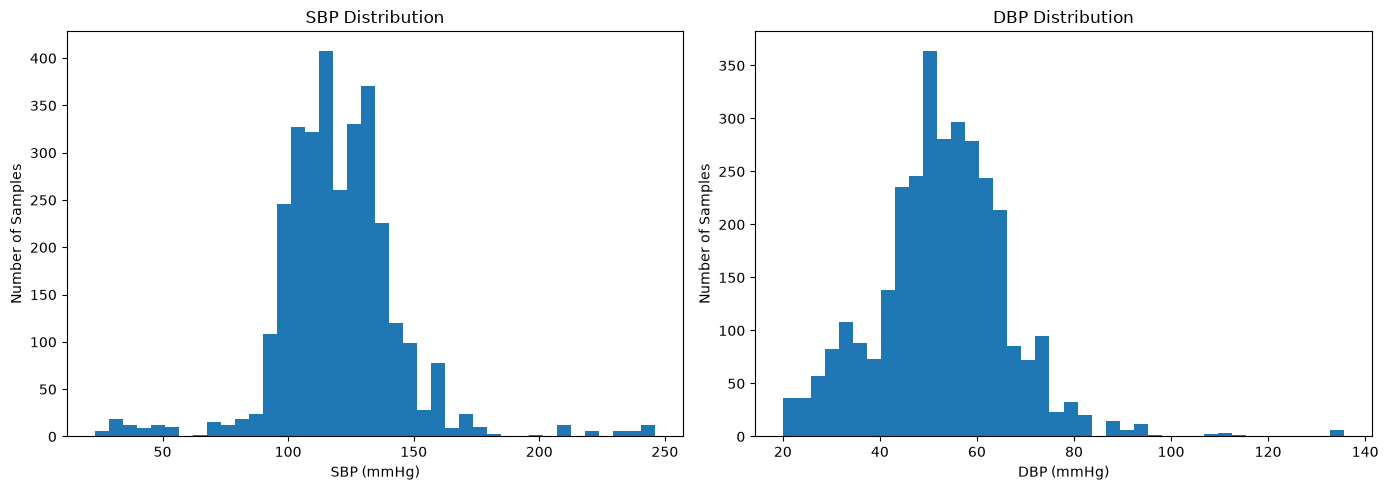

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# SBP
axes[0].hist(df["SBP"], bins=40)
axes[0].set_title("SBP Distribution")
axes[0].set_xlabel("SBP (mmHg)")
axes[0].set_ylabel("Number of Samples")

# DBP
axes[1].hist(df["DBP"], bins=40)
axes[1].set_title("DBP Distribution")
axes[1].set_xlabel("DBP (mmHg)")
axes[1].set_ylabel("Number of Samples")

plt.tight_layout()
plt.show()

In [14]:
# Patient-level BP statistics

patient_stats = df.groupby("patient_id").agg(
    samples=("image", "count"),
    sbp_min=("SBP", "min"),
    sbp_max=("SBP", "max"),
    sbp_mean=("SBP", "mean"),
    dbp_min=("DBP", "min"),
    dbp_max=("DBP", "max"),
    dbp_mean=("DBP", "mean")
)

print(patient_stats.to_string())

            samples     sbp_min     sbp_max    sbp_mean    dbp_min     dbp_max   dbp_mean
patient_id                                                                               
p10020306        72   29.187500  154.875000  103.171267  24.750000   89.875000  58.180512
p10126957        24  129.812500  143.000000  136.984375  33.312500   47.000000  39.734375
p10209410        30  112.250000  134.875000  120.175000  49.875000   54.812500  51.387500
p10952189        36   97.312500  124.437500  109.281250  49.250000   66.187500  56.166667
p11109975        13  105.312500  140.750000  122.063221  54.062500   59.875000  56.826442
p11392990        14   46.437500  101.937500   71.473661  21.500000   34.187500  27.035714
p11944882         1  108.143750  108.143750  108.143750  53.606250   53.606250  53.606250
p12168037        24   36.125000  107.312500   66.484375  25.000000   57.312500  41.187500
p12173569        48   97.437500  212.250000  124.647786  46.937500   54.687500  50.942513
p12188288 

In [15]:
# Find suspicious BP values

suspicious = df[
    (df["SBP"] < 70) |
    (df["SBP"] > 200) |
    (df["DBP"] < 40) |
    (df["DBP"] > 120)
]

print("Suspicious samples:", len(suspicious))

display(
    suspicious[
        ["image", "patient_id", "SBP", "DBP"]
    ].sort_values(["patient_id", "SBP"])
)

Suspicious samples: 526


,image,patient_id,SBP,DBP
0,p10020306_83404654_83404654_0005_0.png,p10020306,29.18750,24.75
1,p10020306_83404654_83404654_0005_1.png,p10020306,29.18750,24.75
2,p10020306_83404654_83404654_0005_2.png,p10020306,29.18750,24.75
3,p10020306_83404654_83404654_0005_3.png,p10020306,29.18750,24.75
4,p10020306_83404654_83404654_0005_4.png,p10020306,29.18750,24.75
...,...,...,...,...
3112,p19313794_88537698_88537698_0013_1.png,p19313794,107.91875,27.35
3113,p19313794_88537698_88537698_0013_2.png,p19313794,107.91875,27.35
3114,p19313794_88537698_88537698_0013_3.png,p19313794,107.91875,27.35
3115,p19313794_88537698_88537698_0013_4.png,p19313794,107.91875,27.35


In [17]:
import os

# Check possible image locations

possible_dirs = [
    "data",
    "data/images",
    "images",
    "scalograms"
]

for folder in possible_dirs:
    if os.path.exists(folder):
        print(f"✅ Found: {folder}")
        print("Number of files:", len(os.listdir(folder)))
    else:
        print(f"❌ Not found: {folder}")

✅ Found: data
Number of files: 3
❌ Not found: data/images
❌ Not found: images
❌ Not found: scalograms


In [18]:
# Check image paths against the CSV

for folder in possible_dirs:
    if os.path.exists(folder):
        df["test_path"] = df["image"].apply(
            lambda x: os.path.join(folder, x)
        )
        
        exists = df["test_path"].apply(os.path.exists)
        
        print("\nFolder:", folder)
        print("Images found:", exists.sum())
        print("Images missing:", (~exists).sum())


Folder: data
Images found: 0
Images missing: 3153


In [19]:
# Number of unique SBP/DBP values per patient

patient_label_check = df.groupby("patient_id").agg(
    unique_sbp=("SBP", "nunique"),
    unique_dbp=("DBP", "nunique"),
    samples=("image", "count")
)

display(patient_label_check.sort_values("unique_sbp", ascending=False).head(20))

,unique_sbp,unique_dbp,samples
patient_id,,,
p13240081,61,58,301
p16566444,49,49,279
p18324626,49,47,253
p17301721,42,42,192
p15649186,36,35,169
p16709726,24,23,121
p15174162,21,21,100
p13016481,18,18,103
p14363499,17,17,97


In [20]:
import os

print("Searching for PNG images...\n")

png_files = []

for root, dirs, files in os.walk("."):
    for file in files:
        if file.lower().endswith(".png"):
            png_files.append(os.path.join(root, file))

print("Total PNG files found:", len(png_files))

print("\nFirst 30 PNG files:")
for path in png_files[:30]:
    print(path)

Searching for PNG images...

Total PNG files found: 3157

First 30 PNG files:
.\gradcam_result.png
.\live_scalogram.png
.\scalograms_final\p10020306_83404654_83404654_0005_0.png
.\scalograms_final\p10020306_83404654_83404654_0005_1.png
.\scalograms_final\p10020306_83404654_83404654_0005_2.png
.\scalograms_final\p10020306_83404654_83404654_0005_3.png
.\scalograms_final\p10020306_83404654_83404654_0005_4.png
.\scalograms_final\p10020306_83404654_83404654_0005_5.png
.\scalograms_final\p10020306_83404654_83404654_0006_0.png
.\scalograms_final\p10020306_83404654_83404654_0006_1.png
.\scalograms_final\p10020306_83404654_83404654_0006_2.png
.\scalograms_final\p10020306_83404654_83404654_0006_3.png
.\scalograms_final\p10020306_83404654_83404654_0006_4.png
.\scalograms_final\p10020306_83404654_83404654_0006_5.png
.\scalograms_final\p10020306_83404654_83404654_0008_0.png
.\scalograms_final\p10020306_83404654_83404654_0009_0.png
.\scalograms_final\p10020306_83404654_83404654_0009_1.png
.\scalogra

In [21]:
target = "p10020306_83404654_83404654_0005_0.png"

matches = []

for root, dirs, files in os.walk("."):
    if target in files:
        matches.append(os.path.join(root, target))

print("Matches found:", len(matches))

for path in matches:
    print(path)

Matches found: 1
.\scalograms_final\p10020306_83404654_83404654_0005_0.png


In [22]:
print("DATA FOLDER CONTENTS:\n")

for item in os.listdir("data"):
    full_path = os.path.join("data", item)

    if os.path.isdir(full_path):
        print("📁", item)
    else:
        print("📄", item)

DATA FOLDER CONTENTS:

📁 labels
📁 processed
📁 raw


In [23]:
# Search project Python files for code related to SBP/DBP label generation

keywords = ["SBP", "DBP", "labels_final", "scalogram"]

for root, dirs, files in os.walk("."):
    for file in files:
        if file.endswith(".py") or file.endswith(".ipynb"):
            path = os.path.join(root, file)

            try:
                with open(path, "r", encoding="utf-8", errors="ignore") as f:
                    text = f.read()

                if any(keyword in text for keyword in keywords):
                    print("\nFOUND:", path)

            except:
                pass


FOUND: .\03_XAI_GradCAM.ipynb

FOUND: .\app.py

FOUND: .\Dataset_Validation.ipynb

FOUND: .\patient_data.py

FOUND: .\Transformer_Training.ipynb

FOUND: .\Transformer_XAI_Cuffless_BP.ipynb

FOUND: .\utils.py

FOUND: .\Webcam.ipynb


In [24]:
from pathlib import Path
import os
import pandas as pd
import numpy as np
import wfdb

# --------------------------------------------------
# Select suspicious sample
# --------------------------------------------------

sample = df.iloc[0]

print("Image:", sample["image"])
print("Patient:", sample["patient_id"])
print("SBP:", sample["SBP"])
print("DBP:", sample["DBP"])

Image: p10020306_83404654_83404654_0005_0.png
Patient: p10020306
SBP: 29.1875
DBP: 24.75


In [25]:
filename = sample["image"].replace(".png", "")

parts = filename.split("_")

patient = parts[0]
record = parts[1]
segment = parts[2] + "_" + parts[3]
window_id = parts[4]

print("Patient :", patient)
print("Record  :", record)
print("Segment :", segment)
print("Window  :", window_id)

Patient : p10020306
Record  : 83404654
Segment : 83404654_0005
Window  : 0


In [26]:
from pathlib import Path

MIMIC_ROOT = Path(
    r"C:\Users\diksh\OneDrive\Documents\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0"
)

record_path = (
    MIMIC_ROOT
    / "waves"
    / patient[:4]
    / patient
    / record
    / segment
)

print("Original record:")
print(record_path)

print("\nExists:", record_path.exists())

Original record:
C:\Users\diksh\OneDrive\Documents\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0\waves\p100\p10020306\83404654\83404654_0005

Exists: False


In [27]:
rec = wfdb.rdrecord(str(record_path))

print("Signal names:")
print(rec.sig_name)

print("\nSampling frequency:")
print(rec.fs)

print("\nSignal shape:")
print(rec.p_signal.shape)

Signal names:
['II', 'V', 'aVR', 'ABP', 'Pleth', 'Resp']

Sampling frequency:
62.4725

Signal shape:
(196480, 6)


In [28]:
channels = [c.upper() for c in rec.sig_name]

print("Channels:")
print(channels)

Channels:
['II', 'V', 'AVR', 'ABP', 'PLETH', 'RESP']


In [29]:
abp_index = channels.index("ABP")

abp = rec.p_signal[:, abp_index]

abp = abp[np.isfinite(abp)]

print("Original ABP statistics:")
print("Min :", np.min(abp))
print("Max :", np.max(abp))
print("Mean:", np.mean(abp))
print("95th percentile:", np.percentile(abp, 95))
print("5th percentile :", np.percentile(abp, 5))

Original ABP statistics:
Min : -1073.8125
Max : 319.4375
Mean: 27.755617941740052
95th percentile: 29.1875
5th percentile : 24.6875


In [30]:
abp_filtered = abp[
    (abp > 20) &
    (abp < 250)
]

print("\nAfter filtering:")
print("Min :", np.min(abp_filtered))
print("Max :", np.max(abp_filtered))
print("95th percentile:", np.percentile(abp_filtered, 95))
print("5th percentile :", np.percentile(abp_filtered, 5))


After filtering:
Min : 20.0625
Max : 249.6875
95th percentile: 29.1875
5th percentile : 24.75


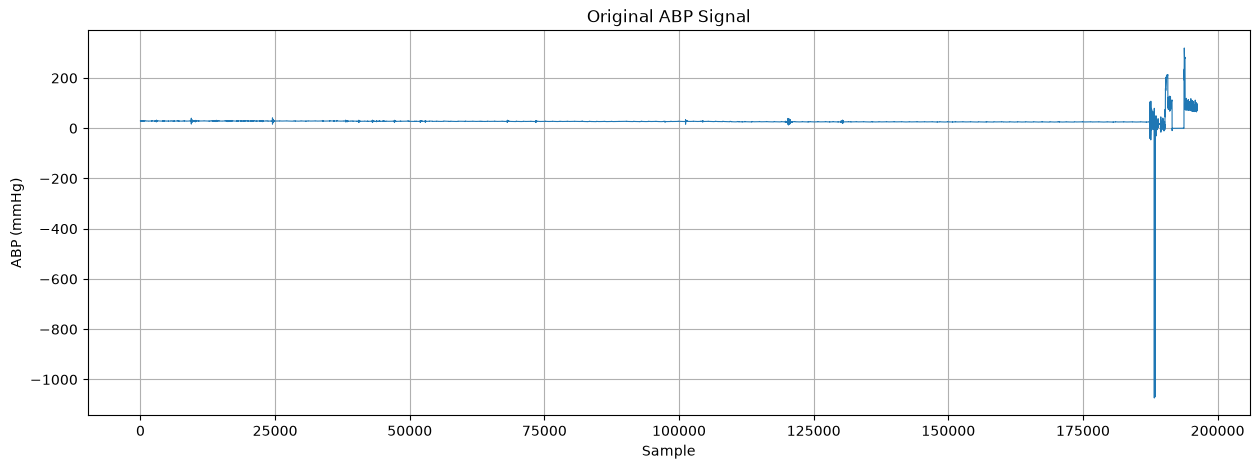

In [31]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(15, 5))

plt.plot(abp, linewidth=0.8)

plt.title("Original ABP Signal")
plt.xlabel("Sample")
plt.ylabel("ABP (mmHg)")
plt.grid(True)

plt.show()

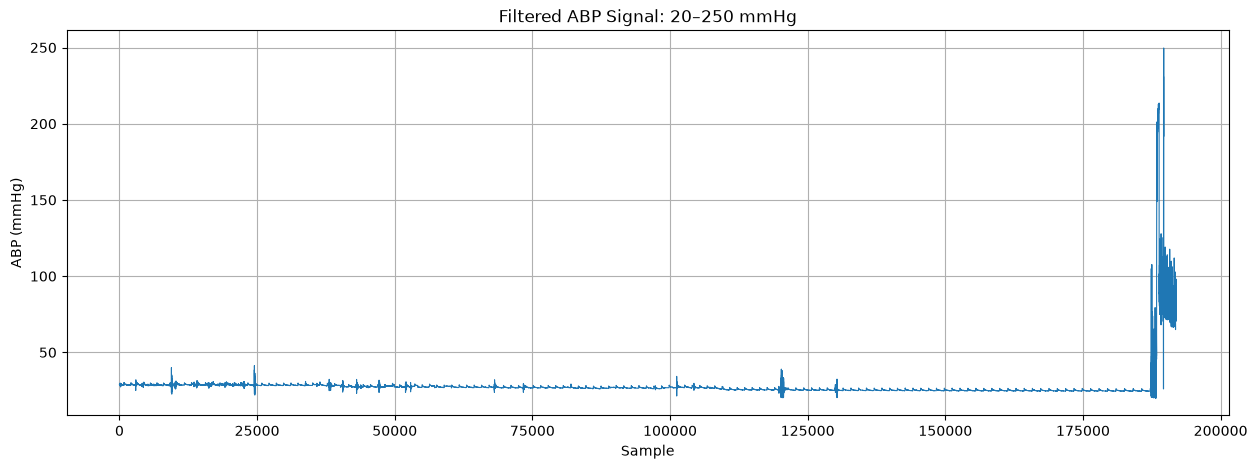

In [32]:
plt.figure(figsize=(15, 5))

plt.plot(abp_filtered, linewidth=0.8)

plt.title("Filtered ABP Signal: 20–250 mmHg")
plt.xlabel("Sample")
plt.ylabel("ABP (mmHg)")
plt.grid(True)

plt.show()

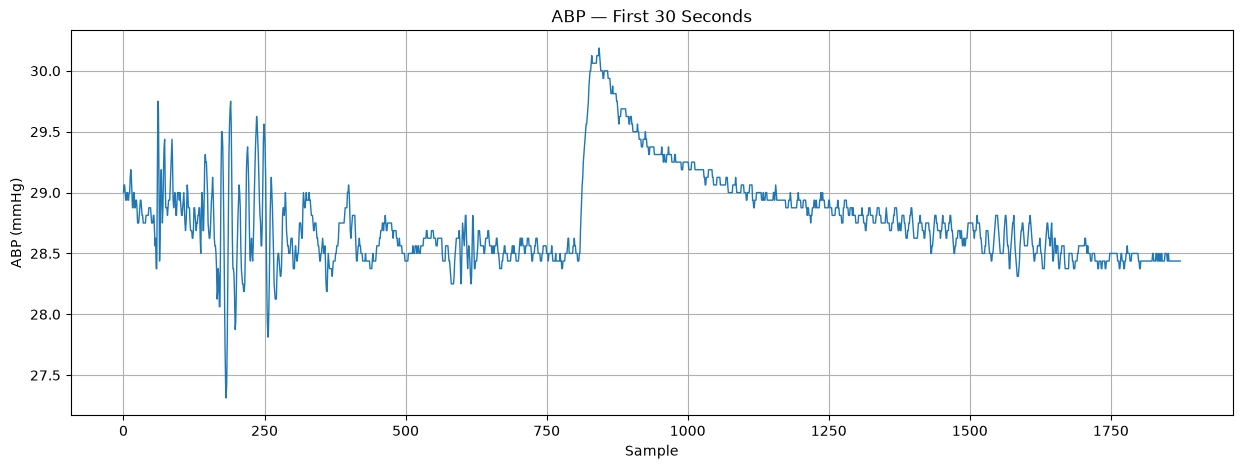

In [33]:
samples_30s = int(rec.fs * 30)

plt.figure(figsize=(15, 5))

plt.plot(
    abp[:samples_30s],
    linewidth=1
)

plt.title("ABP — First 30 Seconds")
plt.xlabel("Sample")
plt.ylabel("ABP (mmHg)")
plt.grid(True)

plt.show()

In [34]:
pleth_index = channels.index("PLETH")

ppg = rec.p_signal[:, pleth_index]

print("PPG statistics")
print("Min :", np.min(ppg))
print("Max :", np.max(ppg))
print("Mean:", np.mean(ppg))
print("Std :", np.std(ppg))

PPG statistics
Min : 0.000244140625
Max : 0.999755859375
Mean: 0.5002901555660881
Std : 0.11344308336544658


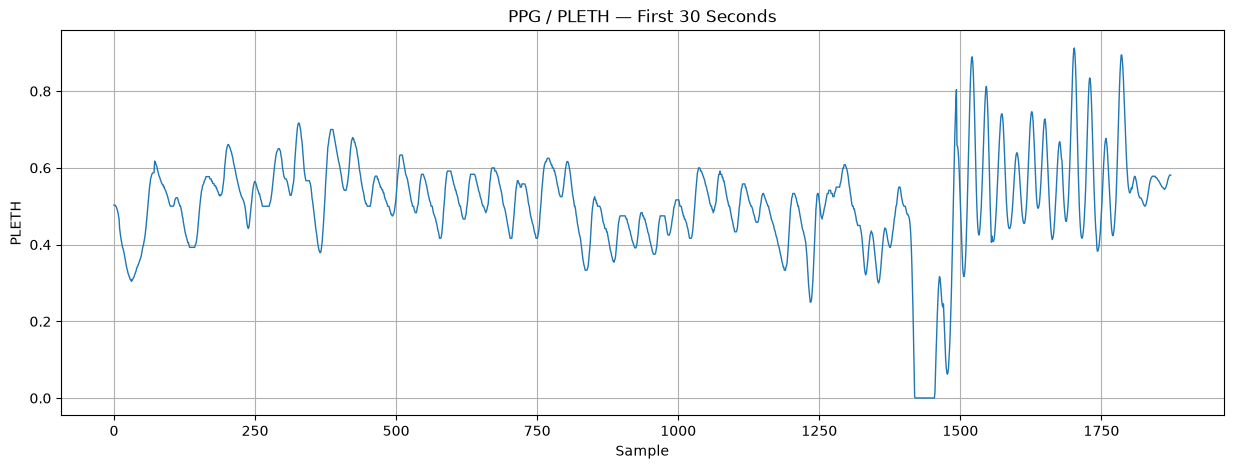

In [35]:
plt.figure(figsize=(15, 5))

plt.plot(
    ppg[:samples_30s],
    linewidth=1
)

plt.title("PPG / PLETH — First 30 Seconds")
plt.xlabel("Sample")
plt.ylabel("PLETH")
plt.grid(True)

plt.show()

In [36]:
WINDOW_SECONDS = 10
WINDOW = int(WINDOW_SECONDS * rec.fs)

print("Sampling frequency:", rec.fs)
print("Samples per window:", WINDOW)
print("Number of possible windows:", len(ppg) // WINDOW)

Sampling frequency: 62.4725
Samples per window: 624
Number of possible windows: 314


In [37]:
for i in range(6):

    start = i * WINDOW
    end = start + WINDOW

    abp_window = abp[start:end]
    ppg_window = ppg[start:end]

    print("=" * 60)
    print("WINDOW:", i)

    print(
        "ABP min:",
        np.min(abp_window),
        "max:",
        np.max(abp_window),
        "mean:",
        np.mean(abp_window),
        "std:",
        np.std(abp_window)
    )

    print(
        "PPG min:",
        np.min(ppg_window),
        "max:",
        np.max(ppg_window),
        "mean:",
        np.mean(ppg_window),
        "std:",
        np.std(ppg_window)
    )

WINDOW: 0
ABP min: 27.3125 max: 29.75 mean: 28.68309294871795 std: 0.30898359560683086
PPG min: 0.303955078125 max: 0.716552734375 mean: 0.529783199994992 std: 0.08330250149818146
WINDOW: 1
ABP min: 28.375 max: 30.1875 mean: 29.025040064102566 std: 0.4414870958099031
PPG min: 0.25 max: 0.625 mean: 0.48482454740084135 std: 0.07282249074460542
WINDOW: 2
ABP min: 28.3125 max: 28.9375 mean: 28.614383012820515 std: 0.15496251593869761
PPG min: 0.000244140625 max: 0.912353515625 mean: 0.49577018542167467 std: 0.189737736641888
WINDOW: 3
ABP min: 28.25 max: 30.0625 mean: 28.966145833333332 std: 0.44091300276616924
PPG min: 0.000244140625 max: 0.80517578125 mean: 0.45900550255408656 std: 0.2007733042425833
WINDOW: 4
ABP min: 25.0 max: 32.0 mean: 28.829627403846153 std: 0.6377217840974939
PPG min: 0.260498046875 max: 0.885498046875 mean: 0.5491869021684695 std: 0.10832383419729984
WINDOW: 5
ABP min: 28.625 max: 30.0 mean: 29.045572916666668 std: 0.31834703395211406
PPG min: 0.324951171875 max: 

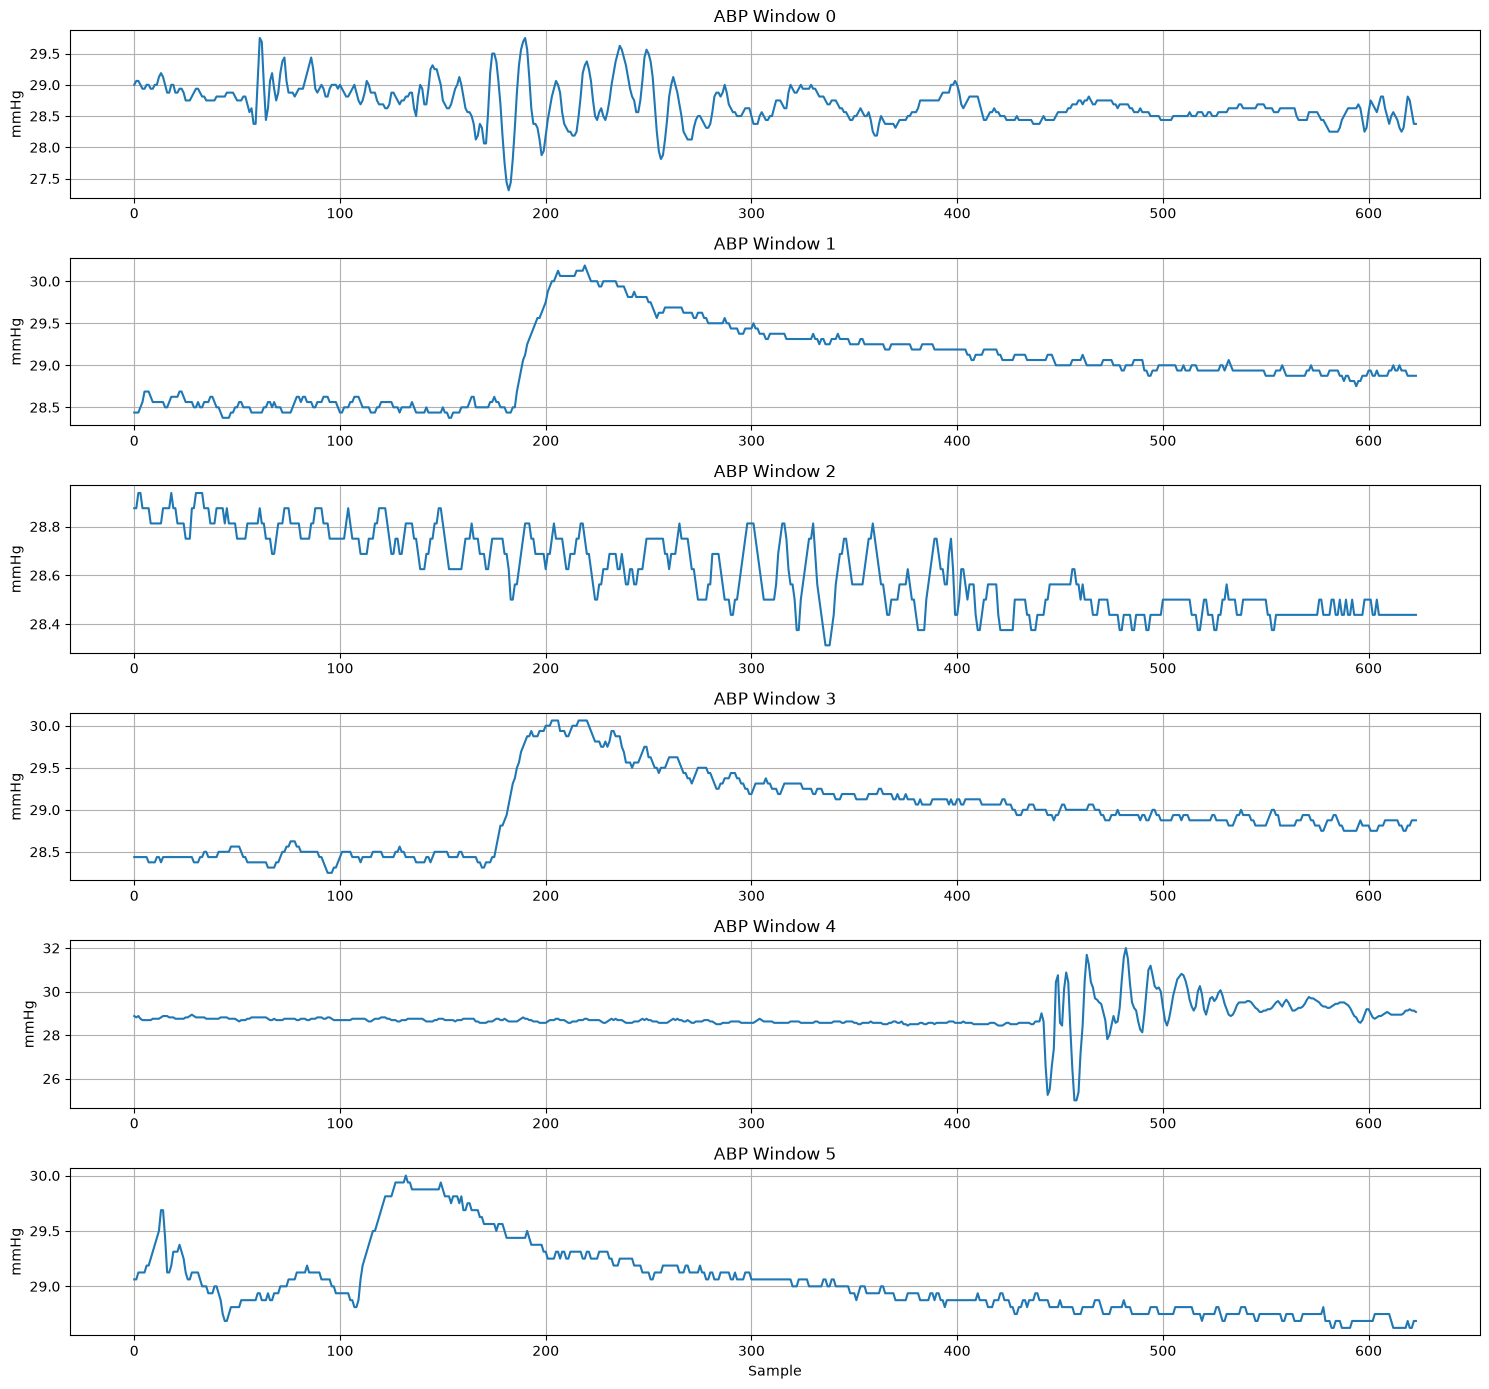

In [38]:
fig, axes = plt.subplots(6, 1, figsize=(15, 14))

for i in range(6):

    start = i * WINDOW
    end = start + WINDOW

    axes[i].plot(abp[start:end])

    axes[i].set_title(f"ABP Window {i}")
    axes[i].set_ylabel("mmHg")
    axes[i].grid(True)

axes[-1].set_xlabel("Sample")

plt.tight_layout()
plt.show()

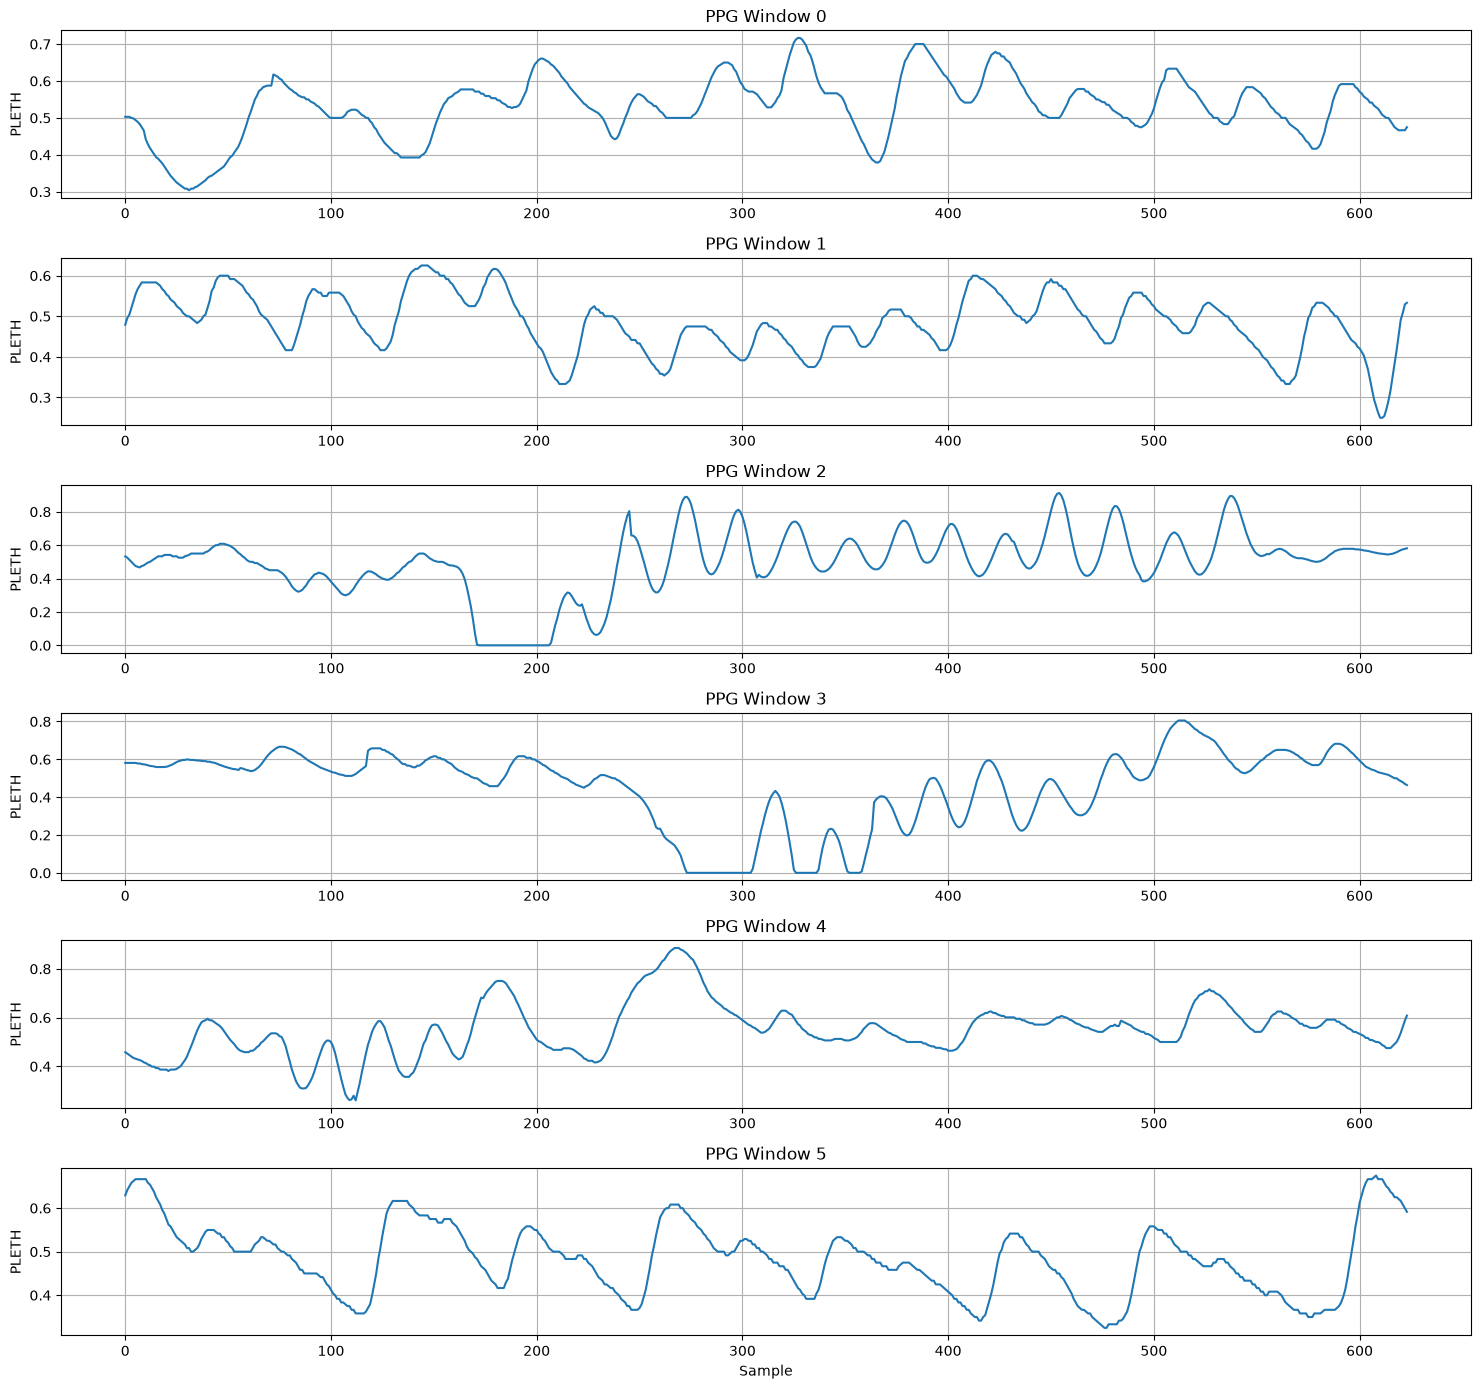

In [39]:
fig, axes = plt.subplots(6, 1, figsize=(15, 14))

for i in range(6):

    start = i * WINDOW
    end = start + WINDOW

    axes[i].plot(ppg[start:end])

    axes[i].set_title(f"PPG Window {i}")
    axes[i].set_ylabel("PLETH")
    axes[i].grid(True)

axes[-1].set_xlabel("Sample")

plt.tight_layout()
plt.show()

In [40]:
# ==========================================
# Scan ALL 10-second windows
# ==========================================

window_results = []

for i in range(len(abp) // WINDOW):

    start = i * WINDOW
    end = start + WINDOW

    abp_window = abp[start:end]

    if len(abp_window) < WINDOW:
        continue

    p5 = np.percentile(abp_window, 5)
    p95 = np.percentile(abp_window, 95)

    window_results.append({
        "window": i,
        "start_sample": start,
        "end_sample": end,
        "p5": p5,
        "p95": p95,
        "mean": np.mean(abp_window),
        "std": np.std(abp_window),
        "min": np.min(abp_window),
        "max": np.max(abp_window),
        "range": np.max(abp_window) - np.min(abp_window),
        "pulse_pressure": p95 - p5
    })

window_df = pd.DataFrame(window_results)

print("Total windows analyzed:", len(window_df))

display(window_df.head(20))

Total windows analyzed: 314


,window,start_sample,end_sample,p5,p95,mean,std,min,max,range,pulse_pressure
0,0,0,624,28.250000,29.240625,28.683093,0.308984,27.3125,29.7500,2.4375,0.990625
1,1,624,1248,28.437500,29.937500,29.025040,0.441487,28.3750,30.1875,1.8125,1.500000
2,2,1248,1872,28.375000,28.875000,28.614383,0.154963,28.3125,28.9375,0.6250,0.500000
3,3,1872,2496,28.375000,29.875000,28.966146,0.440913,28.2500,30.0625,1.8125,1.500000
4,4,2496,3120,28.500000,30.000000,28.829627,0.637722,25.0000,32.0000,7.0000,1.500000
5,5,3120,3744,28.687500,29.812500,29.045573,0.318347,28.6250,30.0000,1.3750,1.125000
6,6,3744,4368,28.000000,28.750000,28.487079,0.274609,27.0000,29.9375,2.9375,0.750000
7,7,4368,4992,28.500000,29.687500,28.906150,0.366831,28.2500,30.5000,2.2500,1.187500
8,8,4992,5616,28.250000,28.740625,28.433694,0.221561,28.1250,29.8125,1.6875,0.490625
9,9,5616,6240,28.500000,29.562500,28.863482,0.353729,28.1875,29.9375,1.7500,1.062500


In [41]:
# ==========================================
# Initial ABP quality screening
# ==========================================

valid_windows = window_df[
    (window_df["p95"] >= 80) &
    (window_df["p95"] <= 200) &
    (window_df["p5"] >= 40) &
    (window_df["p5"] <= 120) &
    (window_df["pulse_pressure"] >= 20)
].copy()

print("Potentially valid windows:", len(valid_windows))

display(valid_windows)

Potentially valid windows: 4


,window,start_sample,end_sample,p5,p95,mean,std,min,max,range,pulse_pressure
306,306,190944,191568,70.778125,112.000000,90.493890,20.843835,-9.5000,127.8125,137.3125,41.221875
311,311,194064,194688,73.696875,105.543750,85.490885,9.943326,71.3125,119.1250,47.8125,31.846875
312,312,194688,195312,70.384375,99.790625,80.912560,9.028159,67.0000,117.6875,50.6875,29.406250
313,313,195312,195936,68.009375,94.096875,76.908454,8.561376,66.3125,111.9375,45.6250,26.087500


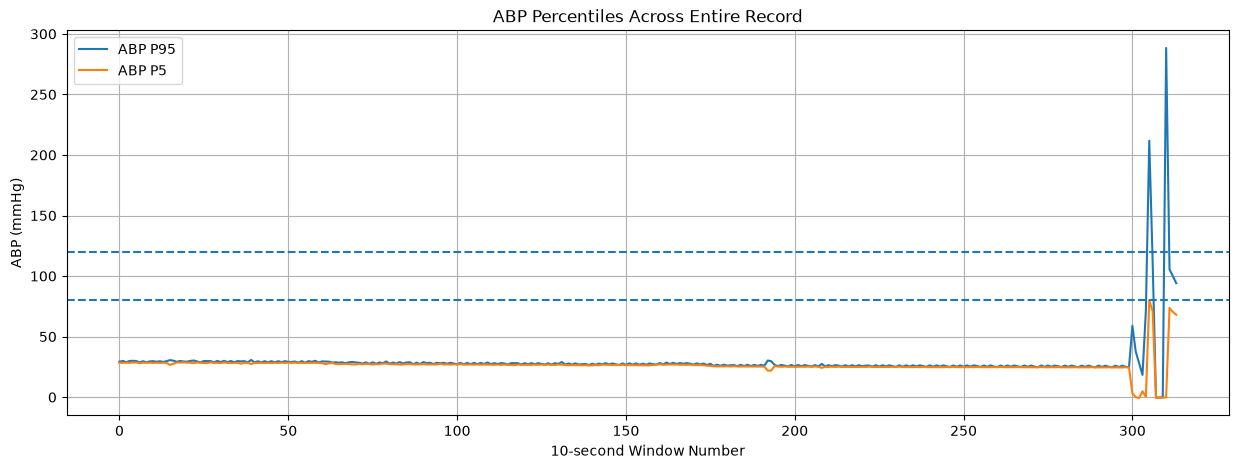

In [42]:
plt.figure(figsize=(15, 5))

plt.plot(
    window_df["window"],
    window_df["p95"],
    label="ABP P95"
)

plt.plot(
    window_df["window"],
    window_df["p5"],
    label="ABP P5"
)

plt.axhline(80, linestyle="--")
plt.axhline(120, linestyle="--")

plt.xlabel("10-second Window Number")
plt.ylabel("ABP (mmHg)")
plt.title("ABP Percentiles Across Entire Record")
plt.legend()
plt.grid(True)

plt.show()

In [43]:
# Sort by pulse pressure to find windows
# with the strongest ABP waveform

best_windows = window_df.sort_values(
    "pulse_pressure",
    ascending=False
).head(20)

display(best_windows)

,window,start_sample,end_sample,p5,p95,mean,std,min,max,range,pulse_pressure
310,310,193440,194064,-0.250000,288.350000,97.016627,118.608004,-0.3750,319.4375,319.8125,288.600000
305,305,190320,190944,80.153125,211.740625,166.454728,52.330539,74.8750,213.5625,138.6875,131.587500
304,304,189696,190320,0.134375,71.656250,19.728866,28.358458,-10.7500,156.1250,166.8750,71.521875
300,300,187200,187824,3.215625,58.959375,30.036358,17.039404,-46.3125,107.6250,153.9375,55.743750
306,306,190944,191568,70.778125,112.000000,90.493890,20.843835,-9.5000,127.8125,137.3125,41.221875
301,301,187824,188448,-0.068750,37.543750,17.598057,63.028164,-1073.8125,79.3750,1153.1875,37.612500
311,311,194064,194688,73.696875,105.543750,85.490885,9.943326,71.3125,119.1250,47.8125,31.846875
312,312,194688,195312,70.384375,99.790625,80.912560,9.028159,67.0000,117.6875,50.6875,29.406250
302,302,188448,189072,-0.712500,27.793750,13.126803,8.835281,-30.5625,49.2500,79.8125,28.506250
313,313,195312,195936,68.009375,94.096875,76.908454,8.561376,66.3125,111.9375,45.6250,26.087500


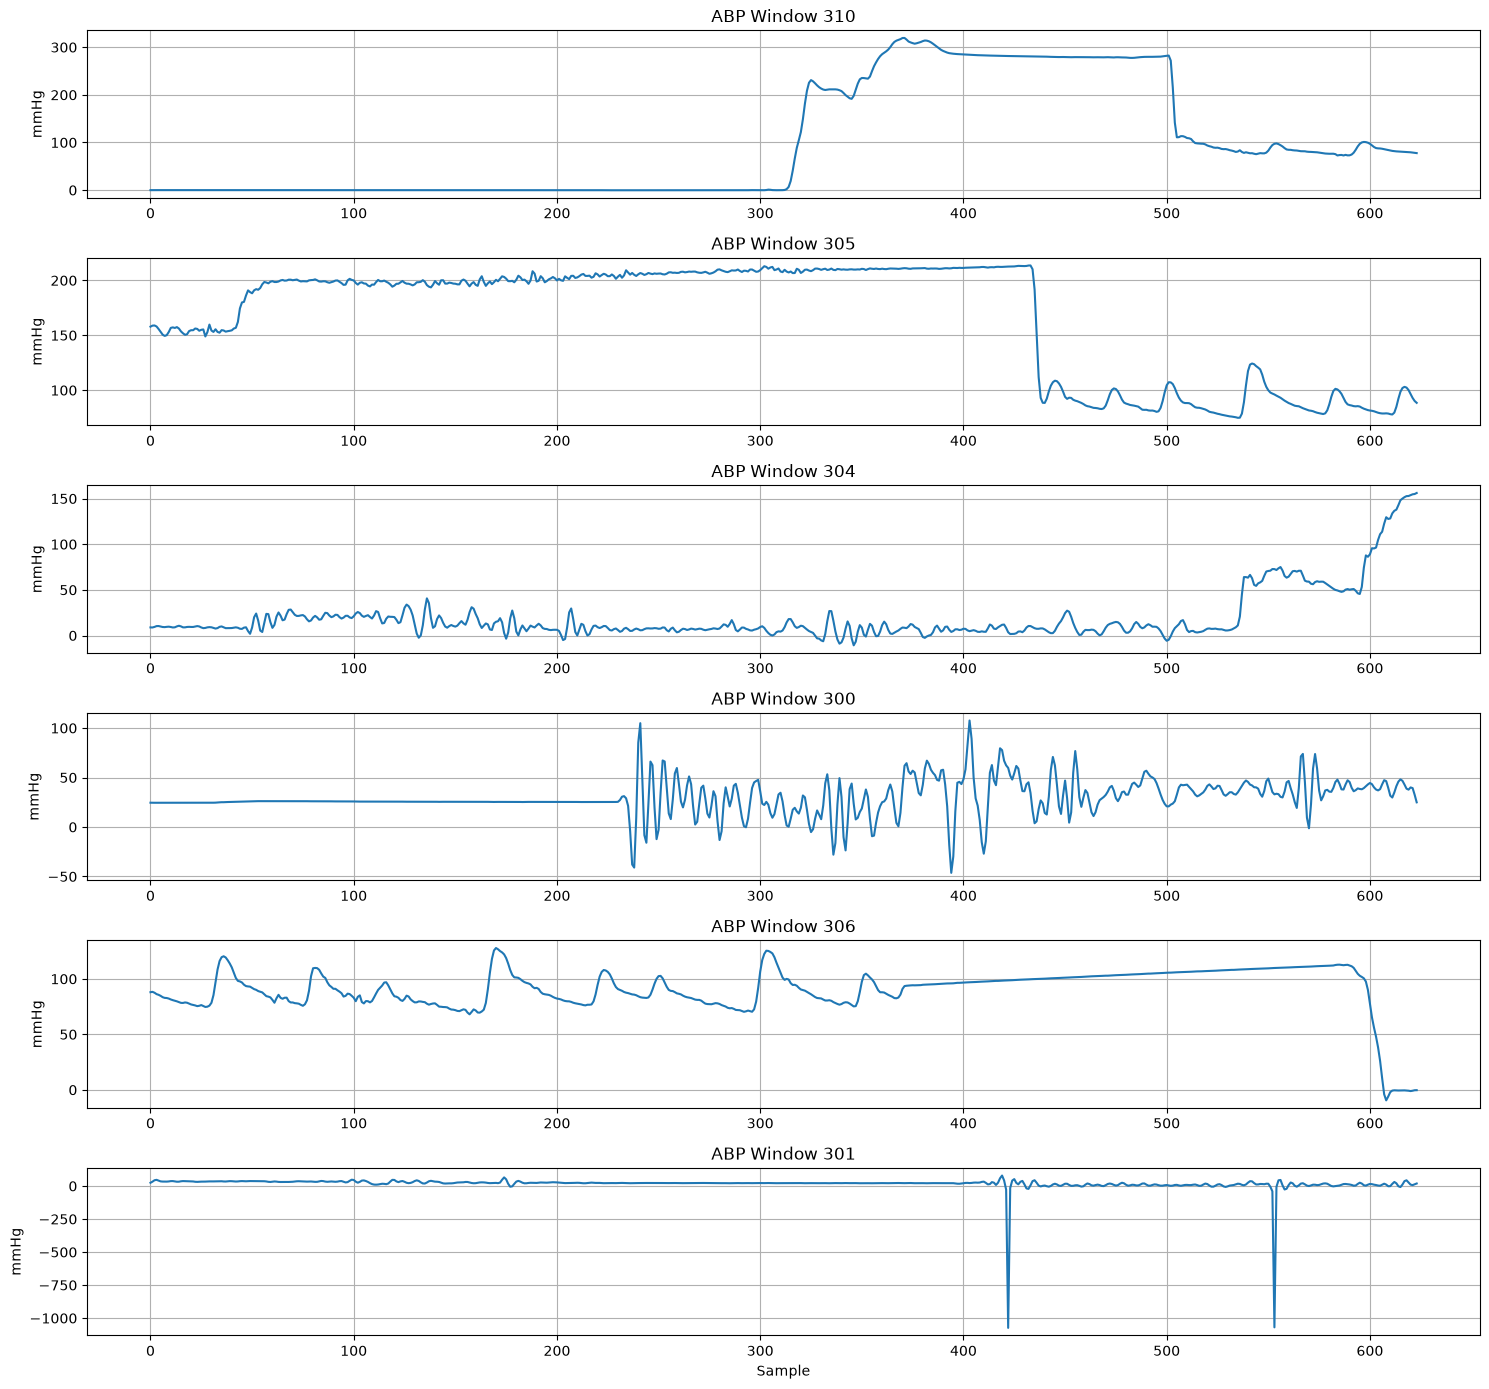

In [44]:
top_windows = best_windows["window"].head(6).tolist()

fig, axes = plt.subplots(
    len(top_windows),
    1,
    figsize=(15, 14)
)

for ax, i in zip(axes, top_windows):

    start = i * WINDOW
    end = start + WINDOW

    ax.plot(abp[start:end])

    ax.set_title(f"ABP Window {i}")
    ax.set_ylabel("mmHg")
    ax.grid(True)

axes[-1].set_xlabel("Sample")

plt.tight_layout()
plt.show()

In [46]:
# ==========================================
# STRONGER ABP QUALITY FILTER
# ==========================================

quality_df = window_df.copy()

valid_fractions = []

for i in quality_df["window"]:

    start = i * WINDOW
    end = start + WINDOW

    w = abp[start:end]

    # Fraction of samples inside reasonable ABP range
    valid_fraction = np.mean(
        (w >= 40) & (w <= 180)
    )

    valid_fractions.append(valid_fraction)


# Add the calculated values
quality_df["valid_fraction"] = valid_fractions


# ------------------------------------------
# Quality filtering
# ------------------------------------------

good_windows = quality_df[
    (quality_df["p5"] >= 45) &
    (quality_df["p95"] <= 180) &
    (quality_df["pulse_pressure"] >= 20) &
    (quality_df["pulse_pressure"] <= 80) &
    (quality_df["valid_fraction"] >= 0.90) &
    (quality_df["min"] >= 30) &
    (quality_df["max"] <= 200)
].copy()


print("Total windows:", len(quality_df))
print("Good windows:", len(good_windows))
print("Rejected windows:", len(quality_df) - len(good_windows))

display(
    good_windows[
        [
            "window",
            "p5",
            "p95",
            "mean",
            "std",
            "min",
            "max",
            "pulse_pressure",
            "valid_fraction"
        ]
    ]
)

Total windows: 314
Good windows: 3
Rejected windows: 311


,window,p5,p95,mean,std,min,max,pulse_pressure,valid_fraction
311,311,73.696875,105.543750,85.490885,9.943326,71.3125,119.1250,31.846875,1.0
312,312,70.384375,99.790625,80.912560,9.028159,67.0000,117.6875,29.406250,1.0
313,313,68.009375,94.096875,76.908454,8.561376,66.3125,111.9375,26.087500,1.0


In [47]:
good_windows["SBP_est"] = good_windows["p95"]
good_windows["DBP_est"] = good_windows["p5"]

display(
    good_windows[
        [
            "window",
            "SBP_est",
            "DBP_est",
            "pulse_pressure"
        ]
    ]
)

,window,SBP_est,DBP_est,pulse_pressure
311,311,105.543750,73.696875,31.846875
312,312,99.790625,70.384375,29.406250
313,313,94.096875,68.009375,26.087500


Accepted windows:
[311, 312, 313]


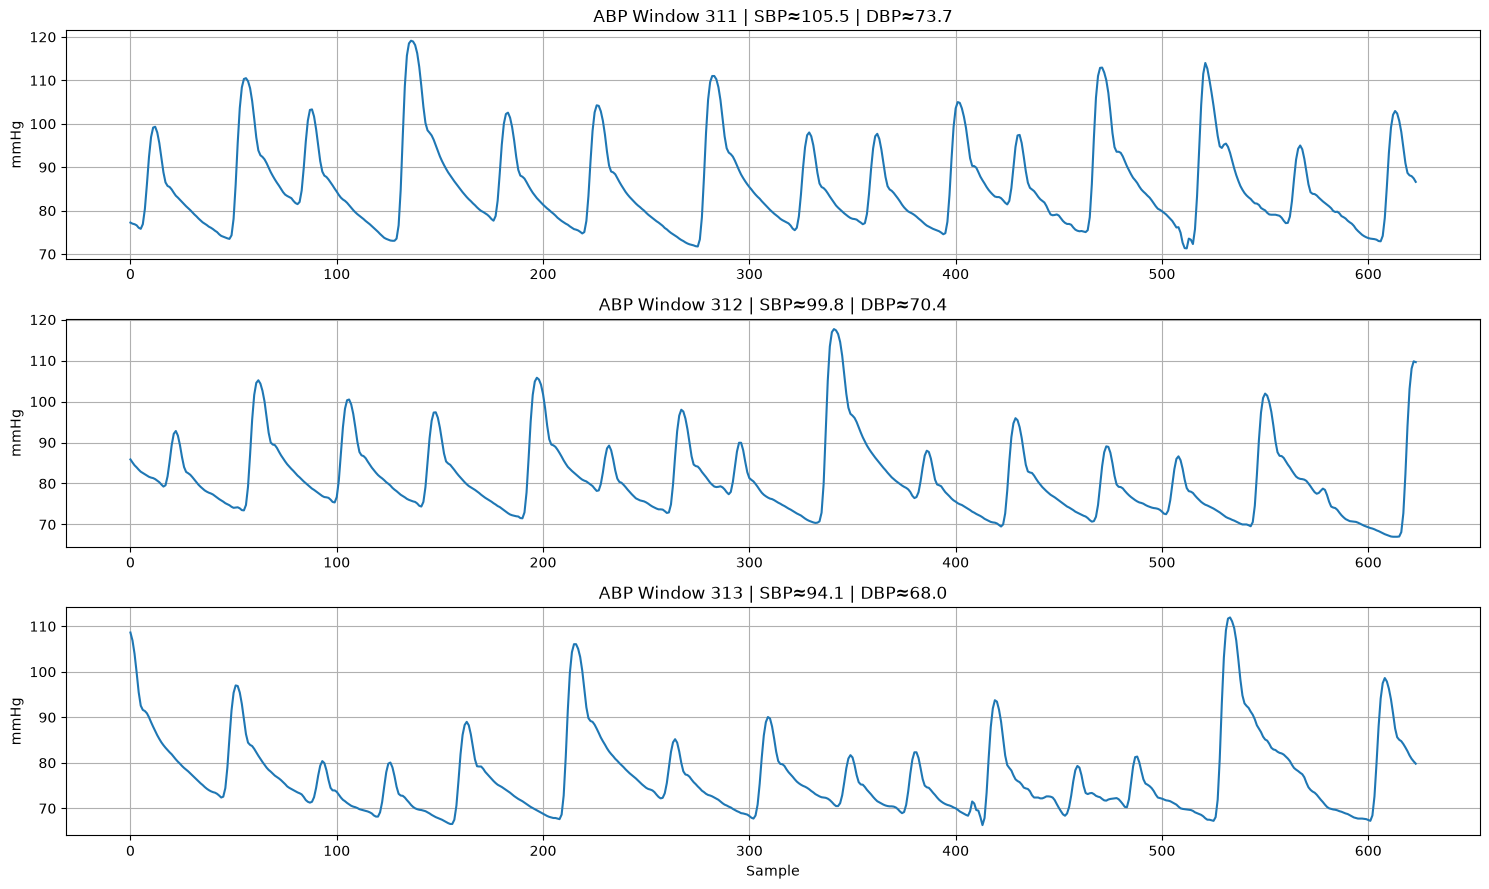

In [48]:
accepted = good_windows["window"].astype(int).tolist()

print("Accepted windows:")
print(accepted)

fig, axes = plt.subplots(
    len(accepted),
    1,
    figsize=(15, max(4, len(accepted) * 3))
)

if len(accepted) == 1:
    axes = [axes]

for ax, i in zip(axes, accepted):

    start = i * WINDOW
    end = start + WINDOW

    ax.plot(abp[start:end])

    ax.set_title(
        f"ABP Window {i} | "
        f"SBP≈{window_df.loc[window_df.window==i, 'p95'].iloc[0]:.1f} | "
        f"DBP≈{window_df.loc[window_df.window==i, 'p5'].iloc[0]:.1f}"
    )

    ax.set_ylabel("mmHg")
    ax.grid(True)

axes[-1].set_xlabel("Sample")

plt.tight_layout()
plt.show()

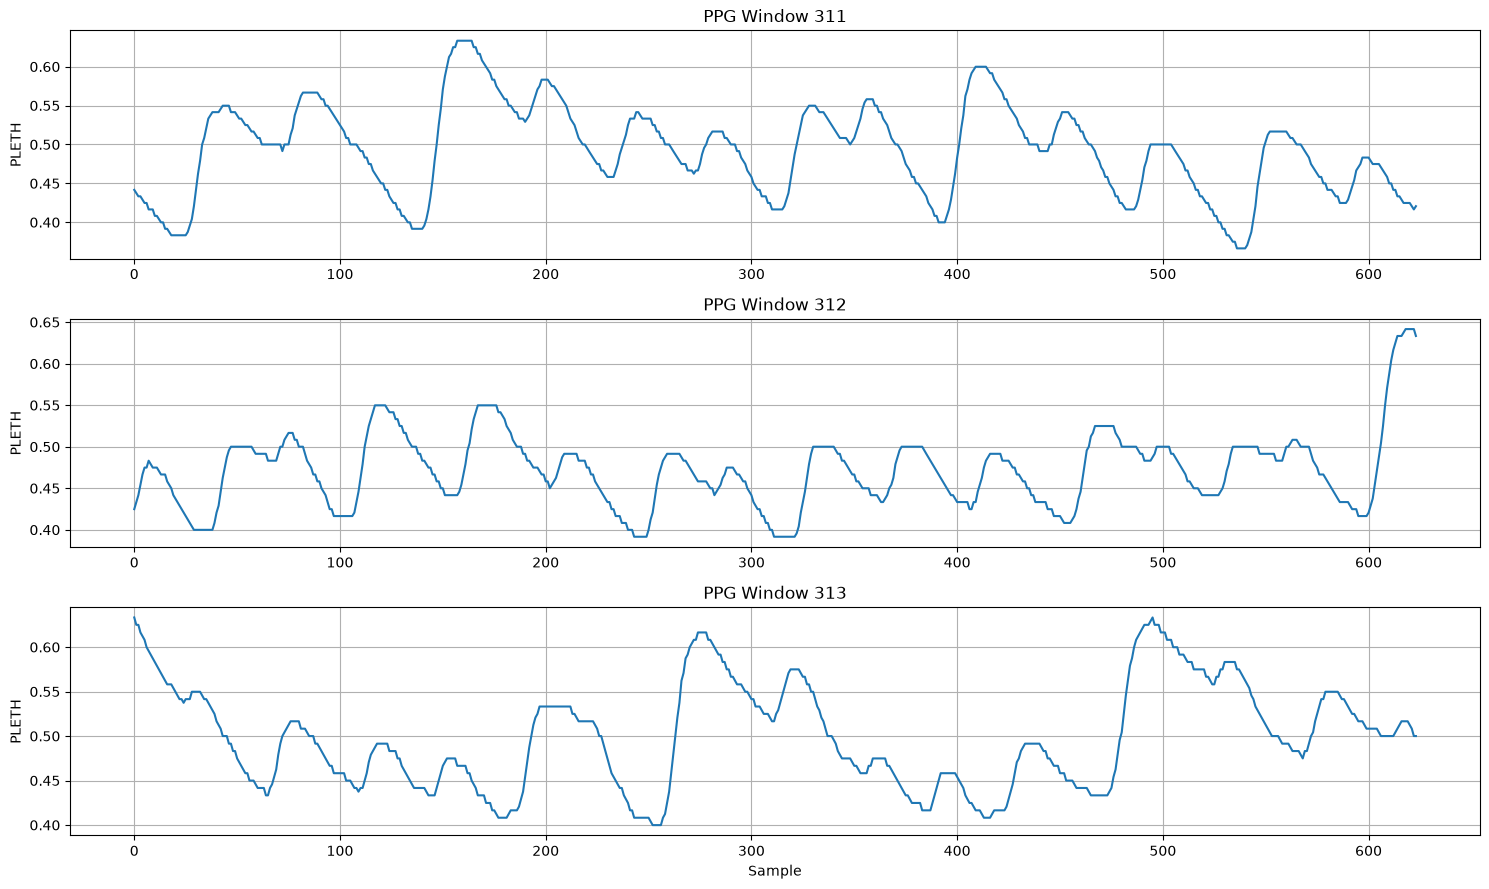

In [49]:
fig, axes = plt.subplots(
    len(accepted),
    1,
    figsize=(15, max(4, len(accepted) * 3))
)

if len(accepted) == 1:
    axes = [axes]

for ax, i in zip(axes, accepted):

    start = i * WINDOW
    end = start + WINDOW

    ax.plot(ppg[start:end])

    ax.set_title(f"PPG Window {i}")
    ax.set_ylabel("PLETH")
    ax.grid(True)

axes[-1].set_xlabel("Sample")

plt.tight_layout()
plt.show()

In [50]:
from scipy.signal import find_peaks
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# BEAT-LEVEL ABP PEAK / TROUGH DETECTION
# ==========================================

beat_results = []

for i in good_windows["window"].astype(int):

    start = i * WINDOW
    end = start + WINDOW

    abp_window = abp[start:end]

    # --------------------------------------
    # Detect systolic peaks
    # --------------------------------------
    peaks, peak_props = find_peaks(
        abp_window,
        distance=int(rec.fs * 0.45),
        prominence=5
    )

    # --------------------------------------
    # Detect diastolic troughs
    # --------------------------------------
    troughs, trough_props = find_peaks(
        -abp_window,
        distance=int(rec.fs * 0.45),
        prominence=3
    )

    peak_values = abp_window[peaks]
    trough_values = abp_window[troughs]

    # Keep physiologically reasonable values
    peak_values = peak_values[
        (peak_values >= 70) &
        (peak_values <= 180)
    ]

    trough_values = trough_values[
        (trough_values >= 40) &
        (trough_values <= 120)
    ]

    beat_results.append({
        "window": i,
        "num_systolic_peaks": len(peak_values),
        "num_diastolic_troughs": len(trough_values),
        "SBP_median": np.median(peak_values) if len(peak_values) > 0 else np.nan,
        "DBP_median": np.median(trough_values) if len(trough_values) > 0 else np.nan,
        "SBP_mean": np.mean(peak_values) if len(peak_values) > 0 else np.nan,
        "DBP_mean": np.mean(trough_values) if len(trough_values) > 0 else np.nan
    })

beat_results_df = pd.DataFrame(beat_results)

display(beat_results_df)

,window,num_systolic_peaks,num_diastolic_troughs,SBP_median,DBP_median,SBP_mean,DBP_mean
0,311,15,14,103.31250,74.90625,104.870833,75.504464
1,312,14,15,96.65625,72.81250,97.008929,73.225000
2,313,14,14,87.09375,68.28125,89.767857,68.915179


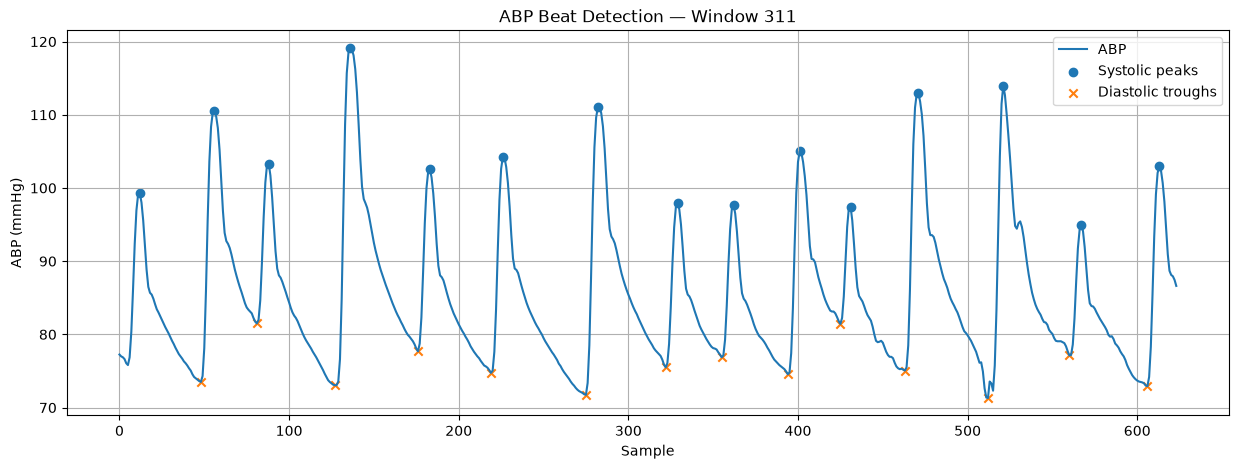

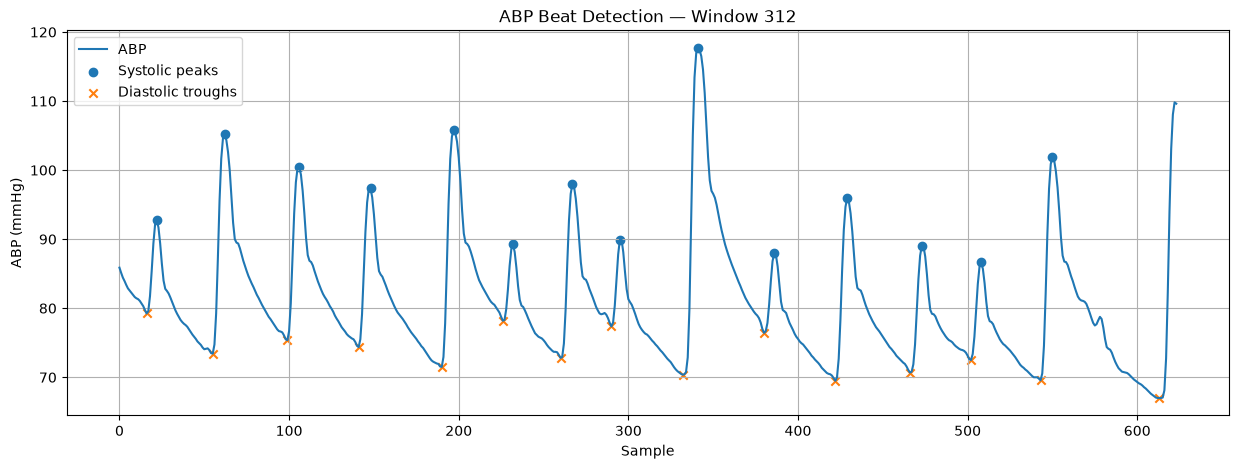

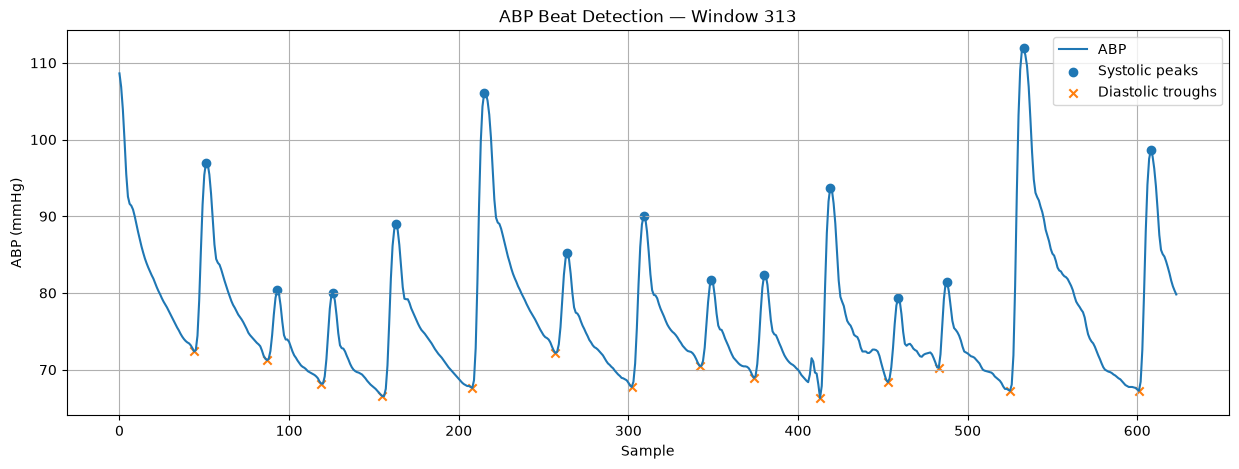

In [51]:
# ==========================================
# VISUALIZE DETECTED ABP BEATS
# ==========================================

for i in good_windows["window"].astype(int):

    start = i * WINDOW
    end = start + WINDOW

    abp_window = abp[start:end]

    peaks, _ = find_peaks(
        abp_window,
        distance=int(rec.fs * 0.45),
        prominence=5
    )

    troughs, _ = find_peaks(
        -abp_window,
        distance=int(rec.fs * 0.45),
        prominence=3
    )

    plt.figure(figsize=(15, 5))

    plt.plot(abp_window, label="ABP")

    plt.scatter(
        peaks,
        abp_window[peaks],
        marker="o",
        label="Systolic peaks"
    )

    plt.scatter(
        troughs,
        abp_window[troughs],
        marker="x",
        label="Diastolic troughs"
    )

    plt.title(f"ABP Beat Detection — Window {i}")
    plt.xlabel("Sample")
    plt.ylabel("ABP (mmHg)")
    plt.grid(True)
    plt.legend()

    plt.show()

In [52]:
comparison = good_windows[
    ["window", "SBP_est", "DBP_est"]
].merge(
    beat_results_df[
        [
            "window",
            "num_systolic_peaks",
            "num_diastolic_troughs",
            "SBP_median",
            "DBP_median",
            "SBP_mean",
            "DBP_mean"
        ]
    ],
    on="window"
)

display(comparison)

,window,SBP_est,DBP_est,num_systolic_peaks,num_diastolic_troughs,SBP_median,DBP_median,SBP_mean,DBP_mean
0,311,105.543750,73.696875,15,14,103.31250,74.90625,104.870833,75.504464
1,312,99.790625,70.384375,14,15,96.65625,72.81250,97.008929,73.225000
2,313,94.096875,68.009375,14,14,87.09375,68.28125,89.767857,68.915179


In [53]:
# ==========================================
# VALIDATED WINDOW-LEVEL BP LABELS
# ==========================================

validated_labels = beat_results_df.copy()

validated_labels = validated_labels[
    [
        "window",
        "num_systolic_peaks",
        "num_diastolic_troughs",
        "SBP_median",
        "DBP_median",
        "SBP_mean",
        "DBP_mean"
    ]
].copy()

# Keep only windows with enough detected beats
validated_labels = validated_labels[
    (validated_labels["num_systolic_peaks"] >= 8) &
    (validated_labels["num_diastolic_troughs"] >= 8) &
    (validated_labels["SBP_median"].notna()) &
    (validated_labels["DBP_median"].notna())
].copy()

print("Validated windows:", len(validated_labels))

display(validated_labels)

Validated windows: 3


,window,num_systolic_peaks,num_diastolic_troughs,SBP_median,DBP_median,SBP_mean,DBP_mean
0,311,15,14,103.31250,74.90625,104.870833,75.504464
1,312,14,15,96.65625,72.81250,97.008929,73.225000
2,313,14,14,87.09375,68.28125,89.767857,68.915179


In [55]:
# ==========================================
# ADD PATIENT / RECORD INFORMATION
# ==========================================

validated_labels["patient"] = patient
validated_labels["record"] = record
validated_labels["fs"] = rec.fs

validated_labels["start_sample"] = (
    validated_labels["window"] * WINDOW
)

validated_labels["end_sample"] = (
    validated_labels["start_sample"] + WINDOW
)

validated_labels["duration_seconds"] = (
    WINDOW / rec.fs
)

validated_labels = validated_labels[
    [
        "patient",
        "record",
        "window",
        "start_sample",
        "end_sample",
        "duration_seconds",
        "num_systolic_peaks",
        "num_diastolic_troughs",
        "SBP_median",
        "DBP_median",
        "SBP_mean",
        "DBP_mean"
    ]
]

display(validated_labels)

,patient,record,window,start_sample,end_sample,duration_seconds,num_systolic_peaks,num_diastolic_troughs,SBP_median,DBP_median,SBP_mean,DBP_mean
0,p10020306,83404654,311,194064,194688,9.988395,15,14,103.31250,74.90625,104.870833,75.504464
1,p10020306,83404654,312,194688,195312,9.988395,14,15,96.65625,72.81250,97.008929,73.225000
2,p10020306,83404654,313,195312,195936,9.988395,14,14,87.09375,68.28125,89.767857,68.915179


In [56]:
validated_labels.to_csv(
    "validated_window_labels_test.csv",
    index=False
)

print("Saved:")
print("validated_window_labels_test.csv")

Saved:
validated_window_labels_test.csv


In [57]:
import os
import glob

# ==========================================
# INSPECT SCALOGRAM NAMES FOR THIS RECORD
# ==========================================

record_prefix = f"{patient}_{record}"

matches = []

for path in glob.glob(
    os.path.join("scalograms_final", "*.png")
):
    
    filename = os.path.basename(path)
    
    if filename.startswith(record_prefix):
        matches.append(filename)

print("Total scalograms for this record:", len(matches))

print("\nFirst 30:")
for x in matches[:30]:
    print(x)

Total scalograms for this record: 72

First 30:
p10020306_83404654_83404654_0005_0.png
p10020306_83404654_83404654_0005_1.png
p10020306_83404654_83404654_0005_2.png
p10020306_83404654_83404654_0005_3.png
p10020306_83404654_83404654_0005_4.png
p10020306_83404654_83404654_0005_5.png
p10020306_83404654_83404654_0006_0.png
p10020306_83404654_83404654_0006_1.png
p10020306_83404654_83404654_0006_2.png
p10020306_83404654_83404654_0006_3.png
p10020306_83404654_83404654_0006_4.png
p10020306_83404654_83404654_0006_5.png
p10020306_83404654_83404654_0008_0.png
p10020306_83404654_83404654_0009_0.png
p10020306_83404654_83404654_0009_1.png
p10020306_83404654_83404654_0009_2.png
p10020306_83404654_83404654_0009_3.png
p10020306_83404654_83404654_0009_4.png
p10020306_83404654_83404654_0009_5.png
p10020306_83404654_83404654_0011_0.png
p10020306_83404654_83404654_0011_1.png
p10020306_83404654_83404654_0011_2.png
p10020306_83404654_83404654_0011_3.png
p10020306_83404654_83404654_0011_4.png
p10020306_834046

In [58]:
# ==========================================
# FIND SCALOGRAMS FOR WINDOWS 311–313
# ==========================================

for w in [311, 312, 313]:

    print("\n" + "=" * 60)
    print("WINDOW:", w)

    token = f"_{w}_"

    window_matches = [
        x for x in matches
        if token in x
    ]

    print("Number of images:", len(window_matches))

    for x in window_matches:
        print(x)


WINDOW: 311
Number of images: 0

WINDOW: 312
Number of images: 0

WINDOW: 313
Number of images: 0


In [59]:
import os

TEST_OUTPUT_DIR = "scalograms_validated_test"
os.makedirs(TEST_OUTPUT_DIR, exist_ok=True)

In [60]:
# ==========================================
# GENERATE VALIDATED SCALOGRAMS
# FOR WINDOWS 311, 312, 313
# ==========================================

import os
import cv2
import pywt
import numpy as np
import pandas as pd

TEST_OUTPUT_DIR = "scalograms_validated_test"
os.makedirs(TEST_OUTPUT_DIR, exist_ok=True)

accepted_windows = [311, 312, 313]

validated_scalogram_labels = []

for w in accepted_windows:

    start = w * WINDOW
    end = start + WINDOW

    # PPG corresponding to THIS 10-sec window
    ppg_window = ppg[start:end]

    if len(ppg_window) != WINDOW:
        print("Skipping window:", w)
        continue

    # --------------------------------------
    # CWT
    # --------------------------------------

    coef, _ = pywt.cwt(
        ppg_window,
        np.arange(1, 129),
        "morl"
    )

    img = np.abs(coef)

    # Normalize
    img -= img.min()

    if img.max() > 0:
        img /= img.max()

    img = (img * 255).astype(np.uint8)

    # Convert to RGB heatmap
    img = cv2.applyColorMap(
        img,
        cv2.COLORMAP_JET
    )

    # Resize for Transformer/CNN
    img = cv2.resize(
        img,
        (224, 224),
        interpolation=cv2.INTER_AREA
    )

    # --------------------------------------
    # Filename
    # --------------------------------------

    filename = (
        f"{patient}_{record}_{segment}_window_{w}.png"
    )

    save_path = os.path.join(
        TEST_OUTPUT_DIR,
        filename
    )

    cv2.imwrite(save_path, img)

    # --------------------------------------
    # Get beat-level BP labels
    # --------------------------------------

    row = beat_results_df[
        beat_results_df["window"] == w
    ].iloc[0]

    validated_scalogram_labels.append({
        "image": filename,
        "patient": patient,
        "record": record,
        "segment": segment,
        "window": w,
        "SBP": row["SBP_median"],
        "DBP": row["DBP_median"]
    })

    print(
        f"Saved window {w}: "
        f"SBP={row['SBP_median']:.2f}, "
        f"DBP={row['DBP_median']:.2f}"
    )


validated_test_df = pd.DataFrame(
    validated_scalogram_labels
)

display(validated_test_df)

Saved window 311: SBP=103.31, DBP=74.91
Saved window 312: SBP=96.66, DBP=72.81
Saved window 313: SBP=87.09, DBP=68.28


,image,patient,record,segment,window,SBP,DBP
0,p10020306_83404654_83404654_0005_window_311.png,p10020306,83404654,83404654_0005,311,103.31250,74.90625
1,p10020306_83404654_83404654_0005_window_312.png,p10020306,83404654,83404654_0005,312,96.65625,72.81250
2,p10020306_83404654_83404654_0005_window_313.png,p10020306,83404654,83404654_0005,313,87.09375,68.28125


In [61]:
validated_test_df.to_csv(
    "validated_scalogram_labels_test.csv",
    index=False
)

print("Saved:")
print("validated_scalogram_labels_test.csv")

Saved:
validated_scalogram_labels_test.csv


In [62]:
import glob

files = glob.glob(
    os.path.join(
        TEST_OUTPUT_DIR,
        "*.png"
    )
)

print("Images generated:", len(files))

for f in files:
    print(f)

Images generated: 3
scalograms_validated_test\p10020306_83404654_83404654_0005_window_311.png
scalograms_validated_test\p10020306_83404654_83404654_0005_window_312.png
scalograms_validated_test\p10020306_83404654_83404654_0005_window_313.png


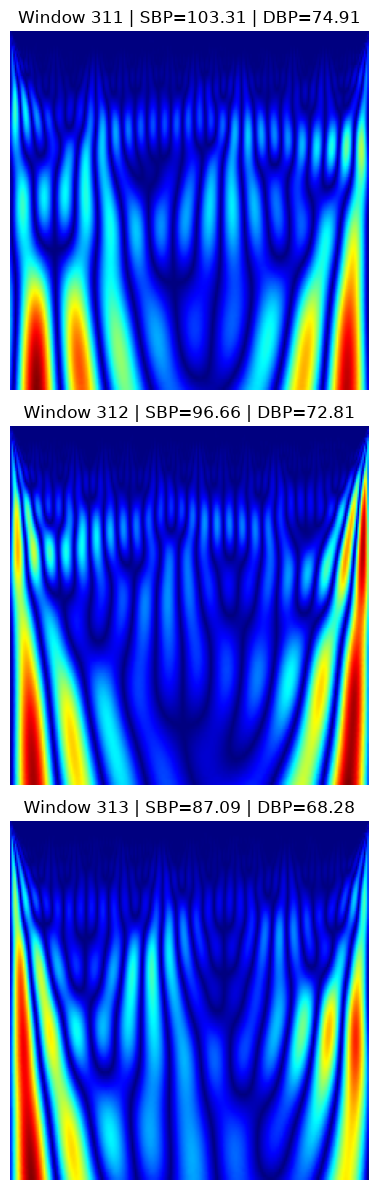

In [63]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    3,
    1,
    figsize=(10, 12)
)

for ax, (_, row) in zip(
    axes,
    validated_test_df.iterrows()
):

    image_path = os.path.join(
        TEST_OUTPUT_DIR,
        row["image"]
    )

    img = cv2.imread(image_path)
    img = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2RGB
    )

    ax.imshow(img)

    ax.set_title(
        f"Window {row['window']} | "
        f"SBP={row['SBP']:.2f} | "
        f"DBP={row['DBP']:.2f}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [65]:
valid_segments = good_windows.copy()

print("Valid segments:", len(valid_segments))
display(valid_segments)

Valid segments: 3


,window,start_sample,end_sample,p5,p95,mean,std,min,max,range,pulse_pressure,valid_fraction,SBP_est,DBP_est
311,311,194064,194688,73.696875,105.543750,85.490885,9.943326,71.3125,119.1250,47.8125,31.846875,1.0,105.543750,73.696875
312,312,194688,195312,70.384375,99.790625,80.912560,9.028159,67.0000,117.6875,50.6875,29.406250,1.0,99.790625,70.384375
313,313,195312,195936,68.009375,94.096875,76.908454,8.561376,66.3125,111.9375,45.6250,26.087500,1.0,94.096875,68.009375


In [66]:
print(good_windows.columns.tolist())

['window', 'start_sample', 'end_sample', 'p5', 'p95', 'mean', 'std', 'min', 'max', 'range', 'pulse_pressure', 'valid_fraction', 'SBP_est', 'DBP_est']


In [68]:
# ============================================================
# PREPARE ACCEPTED WINDOWS FOR FINAL SCALOGRAM GENERATION
# ============================================================

valid_segments = good_windows.copy()

# Metadata of the record we validated
valid_segments["patient"] = "p10020306"
valid_segments["record"] = "83404654"
valid_segments["segment"] = "83404654_0005"

# Use our validated window estimates as BP labels
valid_segments["SBP"] = valid_segments["SBP_est"]
valid_segments["DBP"] = valid_segments["DBP_est"]

print("Valid windows:", len(valid_segments))

display(
    valid_segments[
        [
            "patient",
            "record",
            "segment",
            "window",
            "start_sample",
            "end_sample",
            "SBP",
            "DBP"
        ]
    ]
)

Valid windows: 3


,patient,record,segment,window,start_sample,end_sample,SBP,DBP
311,p10020306,83404654,83404654_0005,311,194064,194688,105.543750,73.696875
312,p10020306,83404654,83404654_0005,312,194688,195312,99.790625,70.384375
313,p10020306,83404654,83404654_0005,313,195312,195936,94.096875,68.009375


In [73]:
from pathlib import Path

WAVE_ROOT = Path(
    r"C:\Users\diksh\OneDrive\Documents\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0"
)

print("WAVE_ROOT exists:", WAVE_ROOT.exists())

WAVE_ROOT exists: True


In [74]:
record_path = (
    WAVE_ROOT /
    "waves" /
    "p100" /
    "p10020306" /
    "83404654" /
    "83404654_0005"
)

print("Record:", record_path)
print("Header exists:", Path(str(record_path) + ".hea").exists())
print("Files in folder:")

for f in record_path.parent.glob("83404654_0005*"):
    print(" ", f.name)

Record: C:\Users\diksh\OneDrive\Documents\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0\waves\p100\p10020306\83404654\83404654_0005
Header exists: True
Files in folder:
  83404654_0005.hea
  83404654_0005e.dat
  83404654_0005p.dat
  83404654_0005r.dat


In [76]:
import numpy as np
from scipy.signal import butter, filtfilt


def preprocess_ppg(ppg, fs):
    """
    Basic PPG preprocessing:
    - Remove NaN/Inf
    - Remove extreme invalid values
    - Bandpass filter
    - Normalize signal
    """

    ppg = np.asarray(ppg, dtype=np.float64)

    # Remove NaN / Inf
    ppg = np.nan_to_num(
        ppg,
        nan=np.nanmedian(ppg),
        posinf=np.nanmedian(ppg),
        neginf=np.nanmedian(ppg)
    )

    # Remove DC component
    ppg = ppg - np.median(ppg)

    # Bandpass filter
    lowcut = 0.5
    highcut = min(8.0, fs / 2 - 0.5)

    if highcut <= lowcut:
        return ppg

    b, a = butter(
        3,
        [lowcut / (fs / 2),
         highcut / (fs / 2)],
        btype="band"
    )

    filtered = filtfilt(b, a, ppg)

    # Normalize
    std = np.std(filtered)

    if std > 0:
        filtered = (filtered - np.mean(filtered)) / std

    return filtered

In [78]:
print("preprocess_ppg exists:", callable(preprocess_ppg))

preprocess_ppg exists: True


In [79]:
import os
import cv2
import pywt
import wfdb
import numpy as np
import pandas as pd
from tqdm import tqdm

OUTPUT_DIR = "scalograms_final"
os.makedirs(OUTPUT_DIR, exist_ok=True)

WINDOW_SECONDS = 10

all_labels = []
saved = 0

for _, row in tqdm(
    valid_segments.iterrows(),
    total=len(valid_segments),
    desc="Generating final scalograms"
):

    patient = row["patient"]
    record = row["record"]
    segment = row["segment"]
    window_id = int(row["window"])

    rrecord_path = (
        WAVE_ROOT /
        "waves" /
        patient[:4] /
        patient /
        record /
        segment
    )

    try:
        rec = wfdb.rdrecord(str(record_path))
    except Exception as e:
        print("Could not read:", record_path)
        print(e)
        continue

    channels = [c.upper() for c in rec.sig_name]

    if "PLETH" in channels:
        idx = channels.index("PLETH")
    elif "PPG" in channels:
        idx = channels.index("PPG")
    else:
        print("No PLETH/PPG:", segment)
        continue

    ppg = rec.p_signal[:, idx]

    try:
        processed = preprocess_ppg(ppg, rec.fs)
    except Exception as e:
        print("Preprocessing failed:", e)
        continue

    WINDOW = int(WINDOW_SECONDS * rec.fs)

    start = window_id * WINDOW
    end = start + WINDOW

    window = processed[start:end]

    if len(window) != WINDOW:
        print("Invalid window:", window_id)
        continue

    # --------------------------------------------------------
    # CWT
    # --------------------------------------------------------

    coef, _ = pywt.cwt(
        window,
        np.arange(1, 129),
        "morl"
    )

    img = np.abs(coef)

    img -= img.min()

    if img.max() > 0:
        img /= img.max()

    img = (img * 255).astype(np.uint8)

    img = cv2.applyColorMap(
        img,
        cv2.COLORMAP_JET
    )

    img = cv2.resize(
        img,
        (224, 224),
        interpolation=cv2.INTER_AREA
    )

    # --------------------------------------------------------
    # SAVE
    # --------------------------------------------------------

    filename = (
        f"{patient}_{record}_{segment}_{window_id}.png"
    )

    save_path = os.path.join(
        OUTPUT_DIR,
        filename
    )

    success = cv2.imwrite(save_path, img)

    if not success:
        print("Failed to save:", save_path)
        continue

    # --------------------------------------------------------
    # LABEL
    # --------------------------------------------------------

    all_labels.append({
        "image": filename,
        "patient": patient,
        "record": record,
        "segment": segment,
        "window": window_id,
        "SBP": row["SBP"],
        "DBP": row["DBP"]
    })

    saved += 1


# ============================================================
# SAVE LABEL CSV
# ============================================================

labels_final = pd.DataFrame(all_labels)

labels_final.to_csv(
    "labels_final.csv",
    index=False
)

print("=" * 60)
print("FINAL DATASET GENERATED")
print("=" * 60)
print("Images Generated :", saved)
print("Labels Saved     :", len(labels_final))
print("=" * 60)

display(labels_final)

Generating final scalograms:   0%|          | 0/3 [00:00<?, ?it/s]

Generating final scalograms: 100%|██████████| 3/3 [00:00<00:00,  4.77it/s]

FINAL DATASET GENERATED
Images Generated : 3
Labels Saved     : 3


,image,patient,record,segment,window,SBP,DBP
0,p10020306_83404654_83404654_0005_311.png,p10020306,83404654,83404654_0005,311,105.543750,73.696875
1,p10020306_83404654_83404654_0005_312.png,p10020306,83404654,83404654_0005,312,99.790625,70.384375
2,p10020306_83404654_83404654_0005_313.png,p10020306,83404654,83404654_0005,313,94.096875,68.009375


In [80]:
# ============================================================
# CHECK WHY WINDOWS ARE BEING REJECTED
# ============================================================

print("Total windows:", len(window_df))

# Show statistics for all windows
display(
    window_df[
        [
            "window",
            "p5",
            "p95",
            "mean",
            "std",
            "min",
            "max",
            "range",
            "pulse_pressure"
        ]
    ].describe()
)

Total windows: 314


,window,p5,p95,mean,std,min,max,range,pulse_pressure
count,314.000000,314.000000,314.000000,314.000000,314.000000,314.000000,314.000000,314.000000,314.000000
mean,156.500000,26.313545,29.667546,27.684070,1.397948,21.866242,31.140924,9.274682,3.354001
std,90.788215,7.442164,20.347427,11.366317,8.405721,62.654403,23.957569,69.584459,18.956340
min,0.000000,-0.712500,-0.375000,-0.421274,0.032230,-1073.812500,-0.375000,0.125000,0.062500
25%,78.250000,24.937500,26.062500,25.255233,0.126689,24.812500,26.312500,0.562500,0.375000
50%,156.500000,26.468750,27.250000,26.814353,0.317598,26.218750,27.500000,1.625000,0.990625
75%,234.750000,27.250000,28.671875,27.804412,0.466529,27.000000,29.125000,1.750000,1.437500
max,313.000000,80.153125,288.350000,166.454728,118.608004,74.875000,319.437500,1153.187500,288.600000


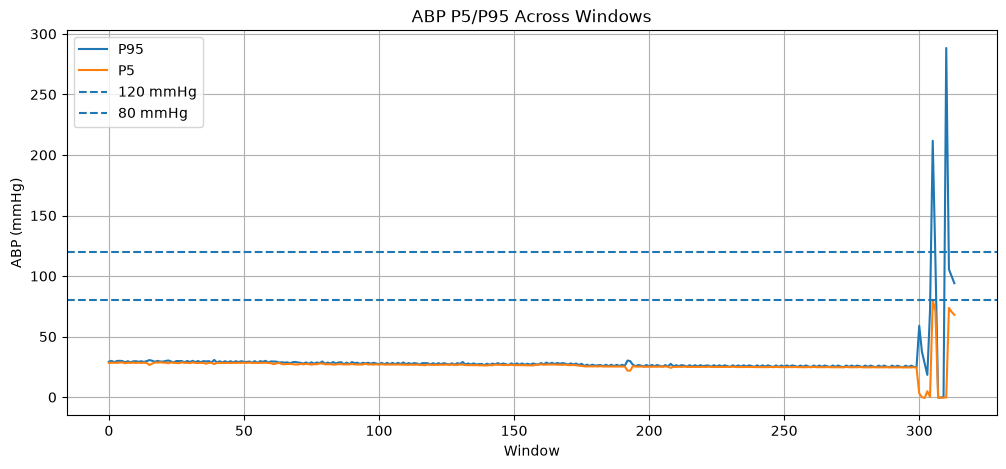

In [81]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    window_df["window"],
    window_df["p95"],
    label="P95"
)

plt.plot(
    window_df["window"],
    window_df["p5"],
    label="P5"
)

plt.axhline(120, linestyle="--", label="120 mmHg")
plt.axhline(80, linestyle="--", label="80 mmHg")

plt.xlabel("Window")
plt.ylabel("ABP (mmHg)")
plt.title("ABP P5/P95 Across Windows")
plt.legend()
plt.grid(True)

plt.show()

In [82]:
# ============================================================
# FIND HOW MANY SEGMENTS HAVE USABLE ABP
# ============================================================

print("Total valid segments available:", len(valid_segments))

display(
    valid_segments[
        ["patient", "record", "segment", "SBP", "DBP"]
    ].head(20)
)

Total valid segments available: 3


,patient,record,segment,SBP,DBP
311,p10020306,83404654,83404654_0005,105.543750,73.696875
312,p10020306,83404654,83404654_0005,99.790625,70.384375
313,p10020306,83404654,83404654_0005,94.096875,68.009375


In [83]:
# ============================================================
# CHECK SEGMENT DISTRIBUTION
# ============================================================

print("Unique patients :", valid_segments["patient"].nunique())
print("Unique records  :", valid_segments["record"].nunique())
print("Total segments  :", len(valid_segments))

print("\nSegments per patient:")
display(
    valid_segments.groupby("patient").size()
    .sort_values(ascending=False)
    .head(20)
)

Unique patients : 1
Unique records  : 1
Total segments  : 3

Segments per patient:


patient
p10020306    3
dtype: int64

In [85]:
# Show all DataFrame variables currently available

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(
            name,
            "→",
            obj.shape,
            "→",
            list(obj.columns)
        )

df → (3153, 5) → ['image', 'SBP', 'DBP', 'patient_id', 'test_path']
patient_stats → (56, 7) → ['samples', 'sbp_min', 'sbp_max', 'sbp_mean', 'dbp_min', 'dbp_max', 'dbp_mean']
suspicious → (526, 4) → ['image', 'SBP', 'DBP', 'patient_id']
patient_label_check → (56, 3) → ['unique_sbp', 'unique_dbp', 'samples']
window_df → (314, 11) → ['window', 'start_sample', 'end_sample', 'p5', 'p95', 'mean', 'std', 'min', 'max', 'range', 'pulse_pressure']
valid_windows → (4, 11) → ['window', 'start_sample', 'end_sample', 'p5', 'p95', 'mean', 'std', 'min', 'max', 'range', 'pulse_pressure']
best_windows → (20, 11) → ['window', 'start_sample', 'end_sample', 'p5', 'p95', 'mean', 'std', 'min', 'max', 'range', 'pulse_pressure']
quality_df → (314, 12) → ['window', 'start_sample', 'end_sample', 'p5', 'p95', 'mean', 'std', 'min', 'max', 'range', 'pulse_pressure', 'valid_fraction']
good_windows → (3, 14) → ['window', 'start_sample', 'end_sample', 'p5', 'p95', 'mean', 'std', 'min', 'max', 'range', 'pulse_pressure'

In [86]:
# ============================================================
# STEP: REBUILD ALL UNIQUE RECORD SEGMENTS FROM ORIGINAL DATA
# ============================================================

import pandas as pd

# Start from the ORIGINAL dataset
source_df = df.copy()

print("Original samples:", len(source_df))
print("Original patients:", source_df["patient_id"].nunique())

# ------------------------------------------------------------
# Extract patient, record, segment and window from image name
# Example:
# p10020306_83404654_83404654_0005_0.png
# ------------------------------------------------------------

def parse_image_name(filename):
    name = str(filename).replace(".png", "")
    parts = name.split("_")

    if len(parts) < 5:
        return pd.Series({
            "patient": None,
            "record": None,
            "segment": None,
            "window": None
        })

    return pd.Series({
        "patient": parts[0],
        "record": parts[1],
        "segment": parts[2] + "_" + parts[3],
        "window": int(parts[4])
    })


parsed = source_df["image"].apply(parse_image_name)

source_df = pd.concat(
    [source_df, parsed],
    axis=1
)

# Remove rows that could not be parsed
source_df = source_df.dropna(
    subset=["patient", "record", "segment"]
)

print("\nParsed samples:", len(source_df))
print("Unique patients:", source_df["patient"].nunique())
print("Unique records:", source_df["record"].nunique())
print("Unique segments:", source_df["segment"].nunique())

# ------------------------------------------------------------
# Create ONE row per waveform segment
# ------------------------------------------------------------

all_segments = (
    source_df[
        [
            "patient",
            "record",
            "segment",
            "SBP",
            "DBP"
        ]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("\nTotal unique segments:", len(all_segments))

display(all_segments.head(20))

Original samples: 3153
Original patients: 56

Parsed samples: 3153
Unique patients: 56
Unique records: 56
Unique segments: 610

Total unique segments: 610


,patient,record,segment,SBP,DBP
0,p10020306,83404654,83404654_0005,29.18750,24.750000
1,p10020306,83404654,83404654_0006,108.25000,59.187500
2,p10020306,83404654,83404654_0008,81.95625,50.375000
3,p10020306,83404654,83404654_0009,104.00000,63.000000
4,p10020306,83404654,83404654_0011,105.00000,59.812500
5,p10020306,83404654,83404654_0012,91.12500,60.231250
6,p10020306,83404654,83404654_0013,94.62500,59.125000
7,p10020306,83404654,83404654_0016,102.00000,59.062500
8,p10020306,83404654,83404654_0017,84.25000,51.496875
9,p10020306,83404654,83404654_0018,105.06250,52.312500


In [90]:
# ============================================================
# SCAN ALL 610 SEGMENTS FOR ABP WINDOWS
# ============================================================

import numpy as np
import pandas as pd
import wfdb
from tqdm import tqdm

WINDOW_SECONDS = 10

all_window_results = []

for _, row in tqdm(
    all_segments.iterrows(),
    total=len(all_segments),
    desc="Scanning all segments"
):

    patient = str(row["patient"])
    record = str(row["record"])
    segment = str(row["segment"])

    # WFDB RECORD BASE PATH
    record_path = (
        WAVE_ROOT /
        "waves" /
        patient[:4] /
        patient /
        record /
        segment
    )

    # Check the actual WFDB header file
    header_path = record_path.with_suffix(".hea")

    if not header_path.exists():
        continue

    try:
        rec = wfdb.rdrecord(str(record_path))
    except Exception as e:
        continue

    channels = [str(c).upper() for c in rec.sig_name]

    # --------------------------------------------------------
    # Find ABP channel
    # --------------------------------------------------------

    if "ABP" not in channels:
        continue

    abp_index = channels.index("ABP")

    abp = rec.p_signal[:, abp_index]

    # --------------------------------------------------------
    # Sampling frequency
    # --------------------------------------------------------

    fs = float(rec.fs)

    WINDOW = int(WINDOW_SECONDS * fs)

    if len(abp) < WINDOW:
        continue

    num_windows = len(abp) // WINDOW

    # --------------------------------------------------------
    # Process every 10-second window
    # --------------------------------------------------------

    for window_id in range(num_windows):

        start = window_id * WINDOW
        end = start + WINDOW

        window = abp[start:end]

        if len(window) != WINDOW:
            continue

        finite_mask = np.isfinite(window)

        if finite_mask.sum() < 0.95 * len(window):
            continue

        clean_window = window[finite_mask]

        p5 = np.percentile(clean_window, 5)
        p95 = np.percentile(clean_window, 95)

        mean = np.mean(clean_window)
        std = np.std(clean_window)

        minimum = np.min(clean_window)
        maximum = np.max(clean_window)

        value_range = maximum - minimum
        pulse_pressure = p95 - p5

        all_window_results.append({
            "patient": patient,
            "record": record,
            "segment": segment,
            "window": window_id,

            "start_sample": start,
            "end_sample": end,

            "p5": p5,
            "p95": p95,
            "mean": mean,
            "std": std,

            "min": minimum,
            "max": maximum,
            "range": value_range,
            "pulse_pressure": pulse_pressure,

            "fs": fs,

            "SBP_label": row["SBP"],
            "DBP_label": row["DBP"]
        })


# ------------------------------------------------------------
# Create dataframe
# ------------------------------------------------------------

all_windows_df = pd.DataFrame(all_window_results)

print("=" * 60)
print("ALL SEGMENTS SCANNED")
print("=" * 60)

print("Source segments :", len(all_segments))
print("Source patients :", all_segments["patient"].nunique())
print("Windows found   :", len(all_windows_df))
print("=" * 60)

if len(all_windows_df) > 0:

    print(
        "Unique patients:",
        all_windows_df["patient"].nunique()
    )

    print(
        "Unique segments:",
        all_windows_df["segment"].nunique()
    )

    display(
        all_windows_df.head(20)
    )

else:

    print("NO WINDOWS FOUND")

Scanning all segments: 100%|██████████| 610/610 [09:19<00:00,  1.09it/s]


ALL SEGMENTS SCANNED
Source segments : 610
Source patients : 56
Windows found   : 619055
Unique patients: 55
Unique segments: 607


,patient,record,segment,window,start_sample,end_sample,p5,p95,mean,std,min,max,range,pulse_pressure,fs,SBP_label,DBP_label
0,p10020306,83404654,83404654_0005,1,624,1248,28.437500,29.937500,28.845853,0.498767,28.2500,30.1875,1.9375,1.500000,62.4725,29.1875,24.75
1,p10020306,83404654,83404654_0005,2,1248,1872,28.500000,29.187500,28.833834,0.192024,28.3125,29.2500,0.9375,0.687500,62.4725,29.1875,24.75
2,p10020306,83404654,83404654_0005,3,1872,2496,28.375000,29.875000,28.774239,0.502187,28.2500,30.0625,1.8125,1.500000,62.4725,29.1875,24.75
3,p10020306,83404654,83404654_0005,4,2496,3120,28.562500,29.125000,28.787059,0.164536,28.5000,29.1875,0.6875,0.562500,62.4725,29.1875,24.75
4,p10020306,83404654,83404654_0005,5,3120,3744,28.500000,30.000000,29.153345,0.654333,25.0000,32.0000,7.0000,1.500000,62.4725,29.1875,24.75
5,p10020306,83404654,83404654_0005,6,3744,4368,28.384375,28.875000,28.651042,0.161213,27.8750,29.1875,1.3125,0.490625,62.4725,29.1875,24.75
6,p10020306,83404654,83404654_0005,7,4368,4992,28.000000,29.687500,28.800581,0.507508,27.0000,30.5000,3.5000,1.687500,62.4725,29.1875,24.75
7,p10020306,83404654,83404654_0005,8,4992,5616,28.250000,28.812500,28.527945,0.167546,28.1250,29.1875,1.0625,0.562500,62.4725,29.1875,24.75
8,p10020306,83404654,83404654_0005,9,5616,6240,28.250000,29.625000,28.788862,0.450769,28.1875,29.9375,1.7500,1.375000,62.4725,29.1875,24.75
9,p10020306,83404654,83404654_0005,10,6240,6864,28.250000,28.687500,28.473057,0.157070,28.1250,29.2500,1.1250,0.437500,62.4725,29.1875,24.75


In [91]:
print("Total windows:", len(all_windows_df))
print("Unique patients:", all_windows_df["patient"].nunique())
print("Unique segments:", all_windows_df["segment"].nunique())

Total windows: 619055
Unique patients: 55
Unique segments: 607


In [89]:
# ============================================================
# DIAGNOSE WAVEFORM PATH
# ============================================================

print("WAVE_ROOT:")
print(WAVE_ROOT)

print("\nFirst segment:")
display(all_segments.head(1))

row = all_segments.iloc[0]

patient = row["patient"]
record = row["record"]
segment = row["segment"]

print("\nPatient :", patient)
print("Record  :", record)
print("Segment :", segment)

test_path = (
    WAVE_ROOT /
    "waves" /
    patient[:4] /
    patient /
    str(record) /
    str(segment)
)

print("\nConstructed path:")
print(test_path)

print("\nExists:", test_path.exists())

# Check parent folders too
print("\nParent exists:", test_path.parent.exists())
print("Record folder exists:", (test_path.parent).exists())

WAVE_ROOT:
C:\Users\diksh\OneDrive\Documents\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0

First segment:


,patient,record,segment,SBP,DBP
0,p10020306,83404654,83404654_0005,29.1875,24.75



Patient : p10020306
Record  : 83404654
Segment : 83404654_0005

Constructed path:
C:\Users\diksh\OneDrive\Documents\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0\waves\p100\p10020306\83404654\83404654_0005

Exists: False

Parent exists: True
Record folder exists: True


In [92]:
# ============================================================
# INSPECT ALL WINDOWS
# ============================================================

print("Total windows:", len(all_windows_df))

display(
    all_windows_df[
        [
            "p5",
            "p95",
            "mean",
            "std",
            "min",
            "max",
            "range",
            "pulse_pressure"
        ]
    ].describe()
)

Total windows: 619055


,p5,p95,mean,std,min,max,range,pulse_pressure
count,619055.000000,619055.000000,619055.000000,619055.000000,619055.000000,619055.000000,619055.000000,619055.000000
mean,54.058665,115.579200,74.581441,19.503978,48.690021,125.375964,76.685943,61.520535
std,22.381924,26.983905,22.431821,8.552080,46.982845,29.778604,54.595085,25.347279
min,-49.375000,-47.812500,-52.825691,0.000000,-1073.937500,-45.562500,0.000000,0.000000
25%,43.956250,101.481250,65.180339,14.150407,40.187500,109.062500,56.000000,44.909375
50%,53.403125,112.865625,72.894030,18.254382,49.687500,122.000000,70.687500,57.862500
75%,61.571875,126.937500,81.183143,24.471657,57.812500,138.062500,90.000000,75.996875
max,461.937500,461.937500,461.937500,229.688441,461.937500,461.937500,1535.562500,479.621875


In [93]:
# ============================================================
# CHECK LABEL DISTRIBUTION
# ============================================================

print("SBP range:")
print(
    all_windows_df["SBP_label"].describe()
)

print("\nDBP range:")
print(
    all_windows_df["DBP_label"].describe()
)

print("\nUnique patients:")
print(
    all_windows_df["patient"].nunique()
)

SBP range:
count    619055.000000
mean        118.516718
std          16.531202
min          22.971875
25%         106.437500
50%         116.437500
75%         129.562500
max         246.250000
Name: SBP_label, dtype: float64

DBP range:
count    619055.000000
mean         49.642195
std          11.149301
min          20.062500
25%          43.000000
50%          50.250000
75%          57.375000
max         135.625000
Name: DBP_label, dtype: float64

Unique patients:
55


In [94]:
# ============================================================
# QUALITY FILTERING — ALL WINDOWS
# ============================================================

quality_all = all_windows_df.copy()

# Fraction of samples inside a physiologically reasonable ABP range
quality_all["valid_fraction"] = (
    (quality_all["min"] >= 30) &
    (quality_all["max"] <= 250)
).astype(float)

print("Total windows:", len(quality_all))

# ------------------------------------------------------------
# FILTER 1: Remove extreme signal artifacts
# ------------------------------------------------------------

filter_artifact = (
    (quality_all["min"] >= 30) &
    (quality_all["max"] <= 250)
)

# ------------------------------------------------------------
# FILTER 2: Reasonable pulse pressure
# ------------------------------------------------------------

filter_pulse = (
    (quality_all["pulse_pressure"] >= 20) &
    (quality_all["pulse_pressure"] <= 100)
)

# ------------------------------------------------------------
# FILTER 3: Reasonable waveform variability
# ------------------------------------------------------------

filter_std = (
    (quality_all["std"] >= 1) &
    (quality_all["std"] <= 40)
)

# ------------------------------------------------------------
# COMBINE FILTERS
# ------------------------------------------------------------

good_windows_all = quality_all[
    filter_artifact &
    filter_pulse &
    filter_std
].copy()

print("=" * 60)
print("QUALITY FILTER RESULTS")
print("=" * 60)

print("Original windows :", len(quality_all))
print("Good windows     :", len(good_windows_all))
print("Rejected windows :", len(quality_all) - len(good_windows_all))

print(
    "Retention        :",
    round(len(good_windows_all) / len(quality_all) * 100, 2),
    "%"
)

display(
    good_windows_all[
        [
            "window",
            "p5",
            "p95",
            "mean",
            "std",
            "min",
            "max",
            "range",
            "pulse_pressure",
            "SBP_label",
            "DBP_label"
        ]
    ].head(20)
)

Total windows: 619055
QUALITY FILTER RESULTS
Original windows : 619055
Good windows     : 531671
Rejected windows : 87384
Retention        : 85.88 %


,window,p5,p95,mean,std,min,max,range,pulse_pressure,SBP_label,DBP_label
311,312,73.143750,104.040625,83.930889,9.371646,70.3750,117.6875,47.3125,30.896875,29.1875,24.7500
312,313,68.312500,93.909375,77.374499,7.986579,66.5625,109.8125,43.2500,25.596875,29.1875,24.7500
313,0,65.259375,94.862500,77.295072,8.330744,64.1875,112.2500,48.0625,29.603125,108.2500,59.1875
314,1,68.759375,99.500000,81.277945,9.036283,67.0625,112.2500,45.1875,30.740625,108.2500,59.1875
315,2,72.500000,103.693750,84.165164,9.393350,69.0625,121.1250,52.0625,31.193750,108.2500,59.1875
316,3,71.153125,103.846875,84.344050,10.727090,68.4375,128.6875,60.2500,32.693750,108.2500,59.1875
317,4,74.946875,108.356250,87.303385,10.440222,69.3125,129.0000,59.6875,33.409375,108.2500,59.1875
318,5,70.868750,111.650000,87.957131,12.155866,64.5625,128.1250,63.5625,40.781250,108.2500,59.1875
319,6,77.187500,112.159375,90.152444,11.193140,74.6250,127.0625,52.4375,34.971875,108.2500,59.1875
320,7,77.446875,116.631250,91.291867,12.207932,74.6250,132.6875,58.0625,39.184375,108.2500,59.1875


In [95]:
# ============================================================
# PATIENT DISTRIBUTION AFTER QUALITY FILTERING
# ============================================================

print("Unique patients:", good_windows_all["patient"].nunique())
print("Unique segments:", good_windows_all["segment"].nunique())

patient_counts = (
    good_windows_all
    .groupby("patient")
    .size()
    .sort_values(ascending=False)
)

display(patient_counts.head(20))

Unique patients: 50
Unique segments: 567


patient
p15649186    39563
p13240081    34998
p16566444    33120
p15857793    30155
p14363499    26607
p10020306    22064
p15342703    21875
p18080257    20867
p17301721    20691
p13016481    18781
p18324626    15455
p16709726    14805
p17744715    14214
p12188288    13842
p16644640    11597
p12173569    11040
p19313794    10904
p14191565    10229
p15174162     9766
p16818396     8279
dtype: int64

In [96]:
# ============================================================
# PATIENT-WISE TRAIN / VALIDATION / TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

# Get unique patients
patients = good_windows_all["patient"].dropna().unique()

print("Total patients:", len(patients))

# ------------------------------------------------------------
# 70% TRAIN, 30% TEMP
# ------------------------------------------------------------

train_patients, temp_patients = train_test_split(
    patients,
    test_size=0.30,
    random_state=42
)

# ------------------------------------------------------------
# 15% VALIDATION, 15% TEST
# ------------------------------------------------------------

val_patients, test_patients = train_test_split(
    temp_patients,
    test_size=0.50,
    random_state=42
)

print("\nPatient split:")
print("Train      :", len(train_patients))
print("Validation :", len(val_patients))
print("Test       :", len(test_patients))

# ------------------------------------------------------------
# CREATE DATAFRAMES
# ------------------------------------------------------------

train_df = good_windows_all[
    good_windows_all["patient"].isin(train_patients)
].copy()

val_df = good_windows_all[
    good_windows_all["patient"].isin(val_patients)
].copy()

test_df = good_windows_all[
    good_windows_all["patient"].isin(test_patients)
].copy()

print("\nWindow split:")
print("Train windows      :", len(train_df))
print("Validation windows :", len(val_df))
print("Test windows       :", len(test_df))

print("\nSegments:")
print("Train segments      :", train_df["segment"].nunique())
print("Validation segments :", val_df["segment"].nunique())
print("Test segments       :", test_df["segment"].nunique())

Total patients: 50

Patient split:
Train      : 35
Validation : 7
Test       : 8

Window split:
Train windows      : 418245
Validation windows : 34558
Test windows       : 78868

Segments:
Train segments      : 444
Validation segments : 43
Test segments       : 80


In [97]:
# ============================================================
# CHECK FOR PATIENT LEAKAGE
# ============================================================

train_set = set(train_patients)
val_set = set(val_patients)
test_set = set(test_patients)

print("Train ∩ Validation :", train_set.intersection(val_set))
print("Train ∩ Test       :", train_set.intersection(test_set))
print("Validation ∩ Test  :", val_set.intersection(test_set))

Train ∩ Validation : set()
Train ∩ Test       : set()
Validation ∩ Test  : set()


In [98]:
# ============================================================
# BALANCE WINDOWS PER SEGMENT
# ============================================================

MAX_WINDOWS_PER_SEGMENT = 20

def balance_segments(df, max_windows=20, random_state=42):
    
    return (
        df.groupby(
            ["patient", "record", "segment"],
            group_keys=False
        )
        .apply(
            lambda x: x.sample(
                n=min(len(x), max_windows),
                random_state=random_state
            )
        )
        .reset_index(drop=True)
    )


train_balanced = balance_segments(
    train_df,
    MAX_WINDOWS_PER_SEGMENT
)

val_balanced = balance_segments(
    val_df,
    MAX_WINDOWS_PER_SEGMENT
)

test_balanced = balance_segments(
    test_df,
    MAX_WINDOWS_PER_SEGMENT
)

print("=" * 60)
print("BALANCED DATASET")
print("=" * 60)

print("Train      :", len(train_balanced))
print("Validation :", len(val_balanced))
print("Test       :", len(test_balanced))

print("\nPatients:")
print("Train      :", train_balanced["patient"].nunique())
print("Validation :", val_balanced["patient"].nunique())
print("Test       :", test_balanced["patient"].nunique())

print("\nSegments:")
print("Train      :", train_balanced["segment"].nunique())
print("Validation :", val_balanced["segment"].nunique())
print("Test       :", test_balanced["segment"].nunique())

BALANCED DATASET
Train      : 6907
Validation : 678
Test       : 1190

Patients:
Train      : 35
Validation : 7
Test       : 8

Segments:
Train      : 444
Validation : 43
Test       : 80


C:\Users\diksh\AppData\Local\Temp\ipykernel_15900\2604725043.py:14: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(
C:\Users\diksh\AppData\Local\Temp\ipykernel_15900\2604725043.py:14: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(
C:\Users\diksh\AppData\Local\Temp\ipykernel_15900\2604725043.py:14: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in 

In [100]:
# ============================================================
# CHECK SBP / DBP DISTRIBUTION
# ============================================================

print("TRAIN SBP")
display(train_balanced["SBP_label"].describe())

print("TRAIN DBP")
display(train_balanced["DBP_label"].describe())

print("\nVALIDATION SBP")
display(val_balanced["SBP_label"].describe())

print("TEST SBP")
display(test_balanced["SBP_label"].describe())

TRAIN SBP


count    6907.000000
mean      122.304857
std        21.051077
min        29.187500
25%       108.250000
50%       121.687500
75%       132.812500
max       246.250000
Name: SBP_label, dtype: float64

TRAIN DBP


count    6907.000000
mean       52.261746
std        11.949081
min        21.500000
25%        44.562500
50%        52.562500
75%        60.209375
max       135.625000
Name: DBP_label, dtype: float64


VALIDATION SBP


count    678.000000
mean     110.075456
std       14.243407
min       75.750000
25%       99.375000
50%      106.812500
75%      116.812500
max      154.437500
Name: SBP_label, dtype: float64

TEST SBP


count    1190.000000
mean      120.031082
std        15.375316
min        91.256250
25%       109.125000
50%       117.562500
75%       130.062500
max       160.937500
Name: SBP_label, dtype: float64

In [101]:
# ============================================================
# CREATE FINAL DATASET STRUCTURE
# ============================================================

from pathlib import Path

DATASET_ROOT = Path("BP_Dataset")

TRAIN_IMG = DATASET_ROOT / "train" / "images"
VAL_IMG   = DATASET_ROOT / "val" / "images"
TEST_IMG  = DATASET_ROOT / "test" / "images"

TRAIN_IMG.mkdir(parents=True, exist_ok=True)
VAL_IMG.mkdir(parents=True, exist_ok=True)
TEST_IMG.mkdir(parents=True, exist_ok=True)

print("Dataset folders created:")
print(TRAIN_IMG)
print(VAL_IMG)
print(TEST_IMG)

Dataset folders created:
BP_Dataset\train\images
BP_Dataset\val\images
BP_Dataset\test\images


In [102]:
# ============================================================
# SAVE LABEL FILES
# ============================================================

train_balanced.to_csv(
    DATASET_ROOT / "train" / "labels.csv",
    index=False
)

val_balanced.to_csv(
    DATASET_ROOT / "val" / "labels.csv",
    index=False
)

test_balanced.to_csv(
    DATASET_ROOT / "test" / "labels.csv",
    index=False
)

print("Labels saved successfully.")

print("\nTrain labels:", len(train_balanced))
print("Val labels  :", len(val_balanced))
print("Test labels :", len(test_balanced))

Labels saved successfully.

Train labels: 6907
Val labels  : 678
Test labels : 1190


Patient : p10020306
Record  : 83404654
Segment : 83404654_0005
Window  : 313
SBP     : 29.1875
DBP     : 24.75

Record path:
C:\Users\diksh\OneDrive\Documents\MIMIC4\MIMIC4\physionet.org\files\mimic4wdb\0.1.0\waves\p100\p10020306\83404654\83404654_0005
Exists: True

Channels: ['II', 'V', 'AVR', 'ABP', 'PLETH', 'RESP']
Sampling frequency: 62.4725

Window samples: 624
Expected: 624


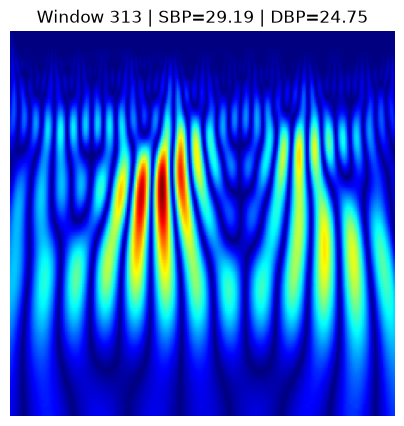


Scalogram shape: (224, 224, 3)


In [105]:
# ============================================================
# TEST ONE SCALOGRAM
# ============================================================

import matplotlib.pyplot as plt
import pywt
import cv2
import numpy as np
import wfdb

sample = train_balanced.iloc[0]

patient = sample["patient"]
record = sample["record"]
segment = sample["segment"]
window_id = int(sample["window"])

print("Patient :", patient)
print("Record  :", record)
print("Segment :", segment)
print("Window  :", window_id)
print("SBP     :", sample["SBP_label"])
print("DBP     :", sample["DBP_label"])

# ------------------------------------------------------------
# FIND RECORD
# ------------------------------------------------------------

record_path = (
    WAVE_ROOT /
    "waves" /
    patient[:4] /
    patient /
    str(record) /
    str(segment)
)

print("\nRecord path:")
print(record_path)
print("Exists:", record_path.with_suffix(".hea").exists())

# ------------------------------------------------------------
# LOAD RECORD
# ------------------------------------------------------------

rec = wfdb.rdrecord(str(record_path))

channels = [c.upper() for c in rec.sig_name]

print("\nChannels:", channels)
print("Sampling frequency:", rec.fs)

# ------------------------------------------------------------
# FIND PPG
# ------------------------------------------------------------

if "PLETH" in channels:
    ppg_index = channels.index("PLETH")
elif "PPG" in channels:
    ppg_index = channels.index("PPG")
else:
    raise ValueError("No PLETH/PPG channel found.")

ppg = rec.p_signal[:, ppg_index]

# ------------------------------------------------------------
# PREPROCESS
# ------------------------------------------------------------

processed = preprocess_ppg(ppg, rec.fs)

# ------------------------------------------------------------
# EXTRACT THE SELECTED 10-SECOND WINDOW
# ------------------------------------------------------------

WINDOW = int(10 * rec.fs)

start = window_id * WINDOW
end = start + WINDOW

window = processed[start:end]

print("\nWindow samples:", len(window))
print("Expected:", WINDOW)

if len(window) != WINDOW:
    raise ValueError("Incorrect window length.")

# ------------------------------------------------------------
# CWT
# ------------------------------------------------------------

scales = np.arange(1, 129)

coef, frequencies = pywt.cwt(
    window,
    scales,
    "morl"
)

img = np.abs(coef)

# Normalize
img -= img.min()

if img.max() > 0:
    img /= img.max()

img = (img * 255).astype(np.uint8)

# Convert to RGB
img = cv2.applyColorMap(
    img,
    cv2.COLORMAP_JET
)

# Resize
img = cv2.resize(
    img,
    (224, 224),
    interpolation=cv2.INTER_AREA
)

# OpenCV BGR → RGB for matplotlib
img_rgb = cv2.cvtColor(
    img,
    cv2.COLOR_BGR2RGB
)

# ------------------------------------------------------------
# DISPLAY
# ------------------------------------------------------------

plt.figure(figsize=(5, 5))

plt.imshow(img_rgb)

plt.title(
    f"Window {window_id} | "
    f"SBP={sample['SBP_label']:.2f} | "
    f"DBP={sample['DBP_label']:.2f}"
)

plt.axis("off")
plt.show()

print("\nScalogram shape:", img.shape)

In [106]:
# ============================================================
# GENERATE FINAL SCALOGRAM DATASET
# ============================================================

import os
import cv2
import pywt
import wfdb
import numpy as np
from tqdm import tqdm


def generate_scalograms(
    dataframe,
    output_dir,
    split_name
):
    
    os.makedirs(output_dir, exist_ok=True)

    saved = 0
    failed = 0

    print("=" * 60)
    print(f"GENERATING {split_name.upper()} SCALOGRAMS")
    print("=" * 60)

    for _, row in tqdm(
        dataframe.iterrows(),
        total=len(dataframe),
        desc=f"{split_name}"
    ):

        try:

            patient = row["patient"]
            record = row["record"]
            segment = row["segment"]
            window_id = int(row["window"])

            # ------------------------------------------------
            # RECORD PATH
            # ------------------------------------------------

            record_path = (
                WAVE_ROOT /
                "waves" /
                patient[:4] /
                patient /
                str(record) /
                str(segment)
            )

            # ------------------------------------------------
            # LOAD RECORD
            # ------------------------------------------------

            rec = wfdb.rdrecord(
                str(record_path)
            )

            channels = [
                c.upper()
                for c in rec.sig_name
            ]

            # ------------------------------------------------
            # FIND PPG
            # ------------------------------------------------

            if "PLETH" in channels:

                ppg_index = channels.index(
                    "PLETH"
                )

            elif "PPG" in channels:

                ppg_index = channels.index(
                    "PPG"
                )

            else:

                failed += 1
                continue

            ppg = rec.p_signal[
                :,
                ppg_index
            ]

            # ------------------------------------------------
            # PREPROCESS
            # ------------------------------------------------

            processed = preprocess_ppg(
                ppg,
                rec.fs
            )

            # ------------------------------------------------
            # EXTRACT WINDOW
            # ------------------------------------------------

            WINDOW = int(
                WINDOW_SECONDS * rec.fs
            )

            start = window_id * WINDOW
            end = start + WINDOW

            window = processed[
                start:end
            ]

            if len(window) != WINDOW:

                failed += 1
                continue

            # ------------------------------------------------
            # CWT
            # ------------------------------------------------

            scales = np.arange(
                1,
                129
            )

            coef, _ = pywt.cwt(
                window,
                scales,
                "morl"
            )

            img = np.abs(coef)

            # ------------------------------------------------
            # NORMALIZE
            # ------------------------------------------------

            img -= img.min()

            if img.max() > 0:

                img /= img.max()

            img = (
                img * 255
            ).astype(
                np.uint8
            )

            # ------------------------------------------------
            # COLORMAP
            # ------------------------------------------------

            img = cv2.applyColorMap(
                img,
                cv2.COLORMAP_JET
            )

            # ------------------------------------------------
            # RESIZE
            # ------------------------------------------------

            img = cv2.resize(
                img,
                (224, 224),
                interpolation=cv2.INTER_AREA
            )

            # ------------------------------------------------
            # SAVE
            # ------------------------------------------------

            filename = (
                f"{patient}_"
                f"{record}_"
                f"{segment}_"
                f"{window_id}.png"
            )

            save_path = (
                os.path.join(
                    output_dir,
                    filename
                )
            )

            success = cv2.imwrite(
                save_path,
                img
            )

            if success:

                saved += 1

            else:

                failed += 1

        except Exception as e:

            failed += 1

    print("\n" + "=" * 60)
    print(f"{split_name.upper()} COMPLETE")
    print("=" * 60)

    print("Expected :", len(dataframe))
    print("Saved    :", saved)
    print("Failed   :", failed)

    return saved

In [107]:
# ============================================================
# GENERATE TRAIN / VAL / TEST
# ============================================================

train_saved = generate_scalograms(
    train_balanced,
    TRAIN_IMG,
    "train"
)

val_saved = generate_scalograms(
    val_balanced,
    VAL_IMG,
    "validation"
)

test_saved = generate_scalograms(
    test_balanced,
    TEST_IMG,
    "test"
)

print("\n" + "=" * 60)
print("FINAL SCALOGRAM SUMMARY")
print("=" * 60)

print("Train :", train_saved)
print("Val   :", val_saved)
print("Test  :", test_saved)
print("Total :", train_saved + val_saved + test_saved)

GENERATING TRAIN SCALOGRAMS


train: 100%|██████████| 6907/6907 [1:41:24<00:00,  1.14it/s]  



TRAIN COMPLETE
Expected : 6907
Saved    : 6907
Failed   : 0
GENERATING VALIDATION SCALOGRAMS


validation: 100%|██████████| 678/678 [06:20<00:00,  1.78it/s]



VALIDATION COMPLETE
Expected : 678
Saved    : 678
Failed   : 0
GENERATING TEST SCALOGRAMS


test: 100%|██████████| 1190/1190 [13:26<00:00,  1.48it/s] 


TEST COMPLETE
Expected : 1190
Saved    : 1190
Failed   : 0

FINAL SCALOGRAM SUMMARY
Train : 6907
Val   : 678
Test  : 1190
Total : 8775


In [108]:
import os
import pandas as pd
import numpy as np
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.13.0+cpu
CUDA available: False


In [109]:
import sys
print(sys.executable)

c:\Program Files\Python314\python.exe
